# 06 — Field Monitoring at Jenny's Vernal Pool Site: Temporal, Non-Stationary, and Edge-Sampling Extensions

This notebook explores three extensions to the baseline GP sampling framework,
each grounded in Binney, Krause & Sukhatme (IJRR 2013).

**Temporal GP**: Can we use measurements from past visits to reconstruct today's soil
moisture field more accurately? We look at this from two angles — extrapolation (predicting
an entirely unvisited date, which turns out to be the wrong question for deployment) and
temporal fusion (using recent history to supplement a partial mission today, which is what
we'd actually want to do in practice).

**Non-stationary spatial kernel (Gibbs)**: Soil moisture near pool edges tends to vary more
sharply than in open upland areas. A Gibbs kernel adapts its spatial lengthscale to
geometry, giving it finer resolution near pool boundaries and coarser resolution in uplands.
This helped — the field is reconstructed more accurately near the pools, which is where the
most ecologically interesting variation occurs.

**Edge sampling**: Binney's paper describes the robot taking measurements as it *drives
between* waypoints, not just at the stops. That's a genuinely good idea and worth
implementing. We've done so here, but we can't properly evaluate it on the current dataset
because Jenny's measurements are only at the 30 GCP stop locations — there's nothing
measured between them. The implementation is correct and ready to use once continuous
transect data is available.

**WIVR/EMSE planning objective**: Binney's paper uses average variance reduction across
the field as its planning objective — matching our WIVR approach rather than mutual
information. We verify the submodularity property that makes the GRG approximation
guarantee valid.

**Data**: 30 GCPs, measured across 6 dates: Jun 10, 11, 16, and 19 (different GCPs on
each date within June), plus all 30 GCPs on Jun 29 and Jul 3 — 90 observations total
with the correct per-GCP timestamps. Jun 22 data in the main xlsx is a depth-calibration
experiment at 2 probe locations and is excluded throughout.


In [1]:
import os, sys, time, math, warnings, base64, io
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as mpl_animation
from matplotlib.backends.backend_agg import FigureCanvasAgg
import networkx as nx
import torch
import gpytorch
import geopandas as gpd
import pandas as pd
from shapely.geometry import LineString
from shapely.ops import unary_union
import shapely
from PIL import Image as PILImage
from IPython.display import HTML, display

warnings.filterwarnings("ignore")
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)
from src.planners import (grg_plan, gp_mutual_information,
                           travel_time_matrix, nearest_neighbor_tour_fixed_end)
print("Imports OK")
import matplotlib.animation as _a
print(f"  animation writers: {_a.writers.list()}")


Imports OK
  animation writers: ['pillow', 'html']


## 0) Configuration

In [2]:
REFS_DIR   = os.path.join(project_root, "refs")
UTM_CRS    = "EPSG:32617"
GCP_SHP    = os.path.join(REFS_DIR, "VPshapefiles", "Vernalpoolgcps20260617_XYTableToPoint.shp")
POOL_BUF   = os.path.join(REFS_DIR, "VPshapefiles", "VPBoundary_PairwiseBuffer.shp")
AREA_BND   = os.path.join(REFS_DIR, "VPshapefiles", "AreaBoundary.shp")
POOL_BOUND = os.path.join(REFS_DIR, "VPshapefiles", "VPBoundary.shp")
XLSX_JUNE  = os.path.join(REFS_DIR, "VP Soil Data.xlsx")
XLSX_JUN29 = os.path.join(REFS_DIR, "VP Soil Data June 29, 2026.xlsx")
XLSX_JUL3  = os.path.join(REFS_DIR, "VP Soil Data July 3, 2026.xlsx")

TRAVEL_SPEED   = 1.0
N_TAU_SPLITS   = 2
GP_TRAIN_ITERS = 320
GP_LR          = 0.02
BASE_NODE      = 0

T_REF    = pd.Timestamp("2026-06-10")
T_JUN29  = (pd.Timestamp("2026-06-29") - T_REF).days   # 19
T_JUL3   = (pd.Timestamp("2026-07-03") - T_REF).days   # 23
T_EXTRAP = 37.0
T_MAX    = T_EXTRAP

RESULTS_DIR = os.path.join(project_root, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Config OK  T_JUN29={T_JUN29}d  T_JUL3={T_JUL3}d")


Config OK  T_JUN29=19d  T_JUL3=23d


## 1) Data — Per-GCP Timestamps

Each GCP was measured on ONE specific date in June.  Col 5 of the per-GCP
summary table (xlsx rows 86–115) gives that date.  Jun 22 data = calibration
experiment; not included.


In [3]:
def _load_june(path):
    df = pd.read_excel(path, header=None)
    s = df.iloc[86:116, [4, 5, 6, 7]].copy()
    s.columns = ["GCP","Date","AvgWC","AvgTemp"]
    s["GCP"]    = s["GCP"].astype(int)
    s["Date"]   = pd.to_datetime(s["Date"])
    s["t_days"] = (s["Date"] - T_REF).dt.days.astype(float)
    return s.sort_values("GCP").reset_index(drop=True)

def _load_later(path, t_days):
    df = pd.read_excel(path, header=None)
    s = df.iloc[38:68, [4, 5, 6]].copy()
    s.columns = ["GCP","AvgWC","AvgTemp"]
    s["GCP"] = s["GCP"].astype(int)
    s["t_days"] = float(t_days)
    return s.sort_values("GCP").reset_index(drop=True)

june_df  = _load_june(XLSX_JUNE)
jun29_df = _load_later(XLSX_JUN29, T_JUN29)
jul3_df  = _load_later(XLSX_JUL3,  T_JUL3)

for t, grp in june_df.groupby("t_days"):
    d = str((T_REF + pd.Timedelta(days=int(t))).date())
    print(f"  t={int(t)}d ({d}): {len(grp)} GCPs -> {sorted(grp['GCP'].tolist())}")
print(f"Jun 29: {len(jun29_df)} GCPs  Jul 3: {len(jul3_df)} GCPs")

gcps  = gpd.read_file(GCP_SHP).to_crs(UTM_CRS)
gcps["gcp_num"] = gcps["Point_ID"].str.extract(r"VERNAL_(\d+)").astype(float)
gcps["is_base"] = gcps["Point_ID"] == "VERNAL_BASE"
gcps["x"] = gcps.geometry.x; gcps["y"] = gcps.geometry.y
pools      = gpd.read_file(POOL_BUF).to_crs(UTM_CRS)
nogo_zone  = unary_union(pools.geometry)
pool_bounds = gpd.read_file(POOL_BOUND).to_crs(UTM_CRS)

base_row = gcps[gcps["is_base"]].iloc[0]
gcp_pts  = gcps[~gcps["is_base"]].copy()
gcp_pts["gcp_num"] = gcp_pts["gcp_num"].astype(int)

june_r  = june_df.rename(columns={"AvgWC":"WC_june","AvgTemp":"Temp_june",
                                    "t_days":"t_june"})[["GCP","WC_june","Temp_june","t_june"]]
jun29_r = jun29_df.rename(columns={"AvgWC":"WC_jun29","AvgTemp":"Temp_jun29"})[["GCP","WC_jun29","Temp_jun29"]]
jul3_r  = jul3_df.rename(columns={"AvgWC":"WC_jul3",  "AvgTemp":"Temp_jul3"})[["GCP","WC_jul3","Temp_jul3"]]
merged = (gcp_pts
    .merge(june_r,  left_on="gcp_num", right_on="GCP", how="left")
    .merge(jun29_r, on="GCP", how="left")
    .merge(jul3_r,  on="GCP", how="left"))
assert len(merged)==30 and merged["WC_june"].notna().all()
merged_sorted = merged.sort_values("gcp_num").reset_index(drop=True)

cx = merged_sorted["x"].mean(); cy = merged_sorted["y"].mean()
merged_sorted["xc"] = merged_sorted["x"] - cx
merged_sorted["yc"] = merged_sorted["y"] - cy
base_xc = base_row["x"] - cx; base_yc = base_row["y"] - cy

PAD = 5.0
xg = np.linspace(merged_sorted["xc"].min()-PAD, merged_sorted["xc"].max()+PAD, 60)
yg = np.linspace(merged_sorted["yc"].min()-PAD, merged_sorted["yc"].max()+PAD, 60)
X1g, X2g = np.meshgrid(xg, yg)
eval_pts_grid = np.column_stack([X1g.ravel(), X2g.ravel()])

print(f"Site: 30 GCPs + BASE  domain {xg[-1]-xg[0]:.0f}x{yg[-1]-yg[0]:.0f} m")
print(f"WC: june [{june_df['AvgWC'].min():.3f},{june_df['AvgWC'].max():.3f}]  "
      f"jun29 [{jun29_df['AvgWC'].min():.3f},{jun29_df['AvgWC'].max():.3f}]  "
      f"jul3 [{jul3_df['AvgWC'].min():.3f},{jul3_df['AvgWC'].max():.3f}]")


  t=0d (2026-06-10): 2 GCPs -> [3, 4]
  t=1d (2026-06-11): 9 GCPs -> [6, 7, 8, 9, 10, 11, 12, 13, 14]
  t=6d (2026-06-16): 8 GCPs -> [15, 16, 18, 19, 22, 23, 26, 27]
  t=9d (2026-06-19): 11 GCPs -> [1, 2, 5, 17, 20, 21, 24, 25, 28, 29, 30]
Jun 29: 30 GCPs  Jul 3: 30 GCPs


Site: 30 GCPs + BASE  domain 71x66 m
WC: june [0.118,0.499]  jun29 [0.187,0.418]  jul3 [0.278,0.522]


## 2) Routing Graph

In [4]:
node_xc = np.concatenate([[base_xc], merged_sorted["xc"].values])
node_yc = np.concatenate([[base_yc], merged_sorted["yc"].values])
node_coords = np.column_stack([node_xc, node_yc])
n_nodes = len(node_coords)

geoms_list = list(nogo_zone.geoms) if nogo_zone.geom_type=="MultiPolygon" else [nogo_zone]
poly_wp_abs = []
for poly in geoms_list:
    simp = poly.simplify(0.5); ctr = poly.centroid
    for pt in list(simp.exterior.coords)[:-1]:
        dx=pt[0]-ctr.x; dy=pt[1]-ctr.y
        nrm=max((dx**2+dy**2)**0.5, 1e-6)
        poly_wp_abs.append((pt[0]+0.7*dx/nrm, pt[1]+0.7*dy/nrm))

node_abs = [(node_xc[i]+cx, node_yc[i]+cy) for i in range(n_nodes)]
vis_pos  = node_abs + poly_wp_abs; n_vis = len(vis_pos)
vis_G = nx.Graph(); vis_G.add_nodes_from(range(n_vis))
for i in range(n_vis):
    for j in range(i+1, n_vis):
        seg = LineString([vis_pos[i], vis_pos[j]])
        if not seg.crosses(nogo_zone):
            vis_G.add_edge(i, j, weight=float(np.linalg.norm(
                np.array(vis_pos[i])-np.array(vis_pos[j]))))

G = nx.Graph(); G.add_nodes_from(range(n_nodes))
n_straight=n_detour=n_infeasible=0
detour_vis_paths={}; detour_edge_set=set()
for i in range(n_nodes):
    for j in range(i+1, n_nodes):
        seg_abs = LineString([node_abs[i], node_abs[j]])
        direct  = float(np.linalg.norm(node_coords[i]-node_coords[j]))
        if not seg_abs.crosses(nogo_zone):
            G.add_edge(i,j,weight=direct/TRAVEL_SPEED,detour=False); n_straight+=1
        else:
            try:
                det=nx.shortest_path_length(vis_G,i,j,weight="weight")
                G.add_edge(i,j,weight=det/TRAVEL_SPEED,detour=True); n_detour+=1
                key=(min(i,j),max(i,j))
                vp=nx.shortest_path(vis_G,i,j,weight="weight")
                detour_vis_paths[key]=[(vis_pos[v][0]-cx,vis_pos[v][1]-cy) for v in vp]
                detour_edge_set.add(key)
            except nx.NetworkXNoPath:
                n_infeasible+=1

tt=travel_time_matrix(G)
np.fill_diagonal(tt,0.0); tt[np.isinf(tt)]=9999.0

rt=tt[BASE_NODE,1:]; rt_fin=rt[rt<9999]
min_rt=float(rt_fin.min())*2; max_rt=float(rt_fin.max())*2
TIME_BUDGETS=[round(min_rt+i*(max_rt-min_rt)/3,0) for i in range(4)]
print(f"Routing: {n_straight} straight  {n_detour} detour  {n_infeasible} infeasible")
print(f"TIME_BUDGETS: {TIME_BUDGETS} s")


Routing: 148 straight  317 detour  0 infeasible
TIME_BUDGETS: [1.0, 47.0, 94.0, 140.0] s


## 3) Static June GP + Helpers

In [5]:
class _ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module  = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.RBFKernel(ard_num_dims=2))
    def forward(self, x):
        return gpytorch.distributions.MultivariateNormal(
            self.mean_module(x), self.covar_module(x))

train_pts  = merged_sorted[["xc","yc"]].values.astype(float)
train_vals = merged_sorted["WC_june"].values.astype(float)
train_x    = torch.tensor(train_pts, dtype=torch.float32)
train_y    = torch.tensor(train_vals, dtype=torch.float32)
y_mean = float(train_y.mean()); y_std = float(train_y.std().clamp_min(1e-6))
train_y_s  = (train_y - y_mean) / y_std

likelihood = gpytorch.likelihoods.GaussianLikelihood()
model_static = _ExactGPModel(train_x, train_y_s, likelihood)
model_static.train(); likelihood.train()
opt = torch.optim.Adam(model_static.parameters(), lr=GP_LR)
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model_static)
for _ in range(GP_TRAIN_ITERS):
    opt.zero_grad(); loss=-mll(model_static(train_x),train_y_s); loss.backward(); opt.step()

model_static.eval(); likelihood.eval()
with torch.no_grad():
    ls = model_static.covar_module.base_kernel.lengthscale.squeeze().numpy()
    os_ = float(model_static.covar_module.outputscale)
    nv  = float(likelihood.noise)
    ls_vals = ls.copy()

nodes_x = torch.tensor(node_coords, dtype=torch.float32)
with torch.no_grad():
    K_all_static = model_static.covar_module(nodes_x).evaluate().numpy()
NOISE_VAR = nv

K_s = K_all_static[1:,1:]+nv*np.eye(30)
K_inv_s = np.linalg.inv(K_s)
alpha_s  = K_inv_s @ train_y_s.numpy()
loo_mu_s  = train_y_s.numpy() - alpha_s/np.diag(K_inv_s)
loo_var_s = np.maximum(1.0/np.diag(K_inv_s), 1e-12)
loo_rmse_static = float(np.sqrt(np.mean(((loo_mu_s*y_std+y_mean)-train_vals)**2)))
loo_nees_static = float(np.mean((train_y_s.numpy()-loo_mu_s)**2/loo_var_s))
cov95_static    = float(np.mean(np.abs(train_y_s.numpy()-loo_mu_s)<1.96*np.sqrt(loo_var_s)))

field_values_s = np.zeros(n_nodes); field_values_s[1:] = train_y_s.numpy()
orig_vals_by_node = {int(r.gcp_num):float(r.WC_june) for _,r in merged_sorted.iterrows()}
SENSOR_NOISE_STD = float(nv**0.5)

# ---- ARD-RBF kernel helper (matches model_static exactly) ----
def ard_rbf(X1, X2):
    diff = X1[:,None,:] - X2[None,:,:]  # (m,n,d)
    sq   = np.sum(diff**2 / ls_vals**2, axis=2)
    return os_ * np.exp(-0.5*sq)

def gp_posterior_at(query_nodes, cond_dict, K_all=None, noise_var=None):
    K_=K_all if K_all is not None else K_all_static
    nv_=noise_var if noise_var is not None else NOISE_VAR
    C=sorted(cond_dict.keys()); Q=list(query_nodes)
    if not C: return np.zeros(len(Q)), np.diag(K_)[np.array(Q,dtype=int)]
    y_c=np.array([cond_dict[i] for i in C])
    K_cc=K_[np.ix_(C,C)]+nv_*np.eye(len(C))
    K_qc=K_[np.ix_(Q,C)]; K_qq_d=np.diag(K_)[np.array(Q,dtype=int)]
    alpha=np.linalg.solve(K_cc,y_c)
    mu=K_qc@alpha
    var=K_qq_d-np.sum(K_qc*np.linalg.solve(K_cc,K_qc.T).T,axis=1)
    return mu, np.maximum(var,1e-12)

def simulate_measurement(node_idx, rng):
    return float(field_values_s[node_idx]+rng.normal(0,SENSOR_NOISE_STD))

def path_metrics(path, measured_dict=None, K_all=None, noise_var=None):
    K_=K_all if K_all is not None else K_all_static
    nv_=noise_var if noise_var is not None else NOISE_VAR
    vis=frozenset(path)-{BASE_NODE}; k=len(vis)
    mi=gp_mutual_information(vis,K_,nv_,frozenset([BASE_NODE])) if k>0 else 0.0
    held=[i for i in range(1,n_nodes) if i not in vis]
    if not held: return {"mi":mi,"k":k,"rmse":0.0,"emse":0.0,"nees":1.0}
    cond={i:(measured_dict[i] if measured_dict and i in measured_dict
              else float(field_values_s[i])) for i in vis}
    mu_s,var_s=gp_posterior_at(held,cond,K_,nv_)
    mu_orig=mu_s*y_std+y_mean
    true_orig=np.array([orig_vals_by_node.get(i,np.nan) for i in held])
    rmse=float(np.sqrt(np.nanmean((mu_orig-true_orig)**2)))
    emse=float(np.mean(var_s)*y_std**2)
    true_s=np.array([field_values_s[i] for i in held])
    return {"mi":mi,"k":k,"rmse":rmse,"emse":emse,
            "nees":float(np.mean((true_s-mu_s)**2/var_s))}

print(f"Static June GP: ls=({ls[0]:.1f},{ls[1]:.1f})m  os={os_:.3f}  nv={nv:.4f}")
print(f"  LOO-RMSE={loo_rmse_static:.4f}  NEES={loo_nees_static:.3f}  cov95={100*cov95_static:.0f}%")


Static June GP: ls=(8.4,7.4)m  os=0.871  nv=0.0360
  LOO-RMSE=0.0589  NEES=1.167  cov95=93%


## Temporal GP

To ask whether historical data helps, we first need a GP that treats space and time jointly.
The SpaceTimeGP uses a product kernel: a 2D spatial RBF for the (x,y) coordinates and a
separate 1D RBF for the time dimension. The product structure means the correlation between
two measurements decays with both spatial distance and time separation simultaneously.

The 90 observations span 6 dates. GCPs were not all measured on the same day within June —
each GCP has the date it was actually visited.

| Date | Days since Jun 10 | GCPs measured |
|------|-------------------|---------------|
| Jun 10 | 0 | 3, 4 |
| Jun 11 | 1 | 6–14 (9 GCPs) |
| Jun 16 | 6 | 15,16,18,19,22,23,26,27 (8 GCPs) |
| Jun 19 | 9 | 1,2,5,17,20,21,24,25,28–30 (11 GCPs) |
| Jun 29 | 19 | all 30 |
| Jul 3 | 23 | all 30 |

Once trained, we can examine what the fitted temporal lengthscale says about the field's
rate of change — this turns out to be important for interpreting the fusion results below.


In [6]:
# 6 date groups, 90 (GCP, date) observations with real per-GCP timestamps
X_st_raw=[]; y_st_raw=[]; date_group=[]

for _,row in merged_sorted.iterrows():
    t_j=float(row["t_june"])
    X_st_raw.append([float(row.xc),float(row.yc),t_j])
    y_st_raw.append(float(row["WC_june"])); date_group.append(t_j)

for _,row in merged_sorted.iterrows():
    X_st_raw.append([float(row.xc),float(row.yc),float(T_JUN29)])
    y_st_raw.append(float(row["WC_jun29"])); date_group.append(float(T_JUN29))

for _,row in merged_sorted.iterrows():
    X_st_raw.append([float(row.xc),float(row.yc),float(T_JUL3)])
    y_st_raw.append(float(row["WC_jul3"])); date_group.append(float(T_JUL3))

X_st_raw=np.array(X_st_raw); y_st_raw=np.array(y_st_raw); date_group=np.array(date_group)
X_st=X_st_raw.copy(); X_st[:,2]/=T_MAX
y_st_mean=float(y_st_raw.mean()); y_st_std=float(y_st_raw.std())
y_st_s=(y_st_raw-y_st_mean)/y_st_std

for t_d in sorted(np.unique(date_group)):
    n=(date_group==t_d).sum()
    print(f"  t={t_d:.0f}d ({str((T_REF+pd.Timedelta(days=int(t_d))).date())}): {n} GCPs")
print(f"WC: [{y_st_raw.min():.3f},{y_st_raw.max():.3f}]  mean={y_st_mean:.3f}  std={y_st_std:.3f}")


  t=0d (2026-06-10): 2 GCPs
  t=1d (2026-06-11): 9 GCPs
  t=6d (2026-06-16): 8 GCPs
  t=9d (2026-06-19): 11 GCPs
  t=19d (2026-06-29): 30 GCPs
  t=23d (2026-07-03): 30 GCPs
WC: [0.118,0.522]  mean=0.345  std=0.080


In [7]:
class SpaceTimeGP(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        k_sp = gpytorch.kernels.RBFKernel(ard_num_dims=2,active_dims=torch.tensor([0,1]))
        k_tm = gpytorch.kernels.RBFKernel(active_dims=torch.tensor([2]))
        self.covar_module = gpytorch.kernels.ScaleKernel(k_sp*k_tm)
    def forward(self, x):
        return gpytorch.distributions.MultivariateNormal(
            self.mean_module(x), self.covar_module(x))

train_x_st=torch.tensor(X_st, dtype=torch.float32)
train_y_st=torch.tensor(y_st_s, dtype=torch.float32)
lik_st=gpytorch.likelihoods.GaussianLikelihood()
model_st=SpaceTimeGP(train_x_st,train_y_st,lik_st)
model_st.train(); lik_st.train()
opt_st=torch.optim.Adam(model_st.parameters(),lr=GP_LR)
mll_st=gpytorch.mlls.ExactMarginalLogLikelihood(lik_st,model_st)
t0=time.perf_counter()
for _ in range(GP_TRAIN_ITERS):
    opt_st.zero_grad()
    loss=-mll_st(model_st(train_x_st),train_y_st)
    loss.backward(); opt_st.step()
model_st.eval(); lik_st.eval()
k_sp2=model_st.covar_module.base_kernel.kernels[0]
k_tm2=model_st.covar_module.base_kernel.kernels[1]
ls_spatial=k_sp2.lengthscale.detach().squeeze().numpy()
ls_temporal=float(k_tm2.lengthscale.detach().squeeze())
ls_days=ls_temporal*T_MAX
nv_st=float(lik_st.noise)
print(f"SpaceTimeGP: spatial ls=({ls_spatial[0]:.1f},{ls_spatial[1]:.1f})m  "
      f"temporal ls={ls_days:.1f}d  nv={nv_st:.4f}")
print(f"(temporal ls={ls_days:.0f}d vs 23d campaign window — "
      f"{'resolves short-term variation' if ls_days<15 else 'dominated by long-term drift'})")


SpaceTimeGP: spatial ls=(8.6,7.9)m  temporal ls=76.9d  nv=0.4857
(temporal ls=77d vs 23d campaign window — dominated by long-term drift)


## Temporal Extrapolation: A Diagnostic, Not a Deployment Test

Before looking at fusion, it's useful to check whether the temporal GP can extrapolate
at all — that is, predict a date it has never seen from the other five dates.
This isn't what we'd do in practice (a real mission always starts fresh on the day),
but it tells us whether the GP's temporal kernel is picking up any meaningful signal
or just treating all dates as spatially similar.

We hold out each date in turn, refit the GP on the remaining five, and compare its
predictions to simply using the historical mean as a flat prediction.


In [8]:
def train_and_predict_st(X_tr, y_tr_s, X_te, y_te_orig, y_m, y_s):
    X_tr_t=torch.tensor(X_tr,dtype=torch.float32)
    y_tr_t=torch.tensor(y_tr_s,dtype=torch.float32)
    X_te_t=torch.tensor(X_te,dtype=torch.float32)
    lik_f=gpytorch.likelihoods.GaussianLikelihood()
    m_f=SpaceTimeGP(X_tr_t,y_tr_t,lik_f)
    m_f.train(); lik_f.train()
    opt_f=torch.optim.Adam(m_f.parameters(),lr=GP_LR)
    mll_f=gpytorch.mlls.ExactMarginalLogLikelihood(lik_f,m_f)
    for _ in range(GP_TRAIN_ITERS):
        opt_f.zero_grad(); loss=-mll_f(m_f(X_tr_t),y_tr_t); loss.backward(); opt_f.step()
    m_f.eval(); lik_f.eval()
    with torch.no_grad():
        pred=m_f(X_te_t); mu_s=pred.mean.numpy(); var_s=pred.variance.numpy()
    mu_orig=mu_s*y_s+y_m
    rmse=float(np.sqrt(np.mean((mu_orig-y_te_orig)**2)))
    nees=float(np.mean(((y_te_orig-y_m)/y_s-mu_s)**2/np.maximum(var_s,1e-12)))
    return rmse, nees

holdout_dates=[("Jun 29",float(T_JUN29)),("Jul 3",float(T_JUL3)),
               ("Jun 16",6.0),("Jun 19",9.0)]
loo_extrap={}
for label,t_ho in holdout_dates:
    mask_ho=date_group==t_ho; mask_tr=~mask_ho
    rmse_gp,nees_gp=train_and_predict_st(
        X_st[mask_tr],y_st_s[mask_tr],X_st[mask_ho],y_st_raw[mask_ho],y_st_mean,y_st_std)
    naive=float(np.mean(y_st_raw[mask_tr]))
    rmse_naive=float(np.sqrt(np.mean((naive-y_st_raw[mask_ho])**2)))
    loo_extrap[label]={"n":int(mask_ho.sum()),"gp_rmse":rmse_gp,
                       "naive_rmse":rmse_naive,"nees":nees_gp}

print("=== Temporal extrapolation LOO ===")
print(f"  {'Holdout':>8}  {'n':>3}  {'GP':>8}  {'Naive':>8}  {'Winner':>10}  {'NEES':>7}")
for lab,r in loo_extrap.items():
    w="GP" if r["gp_rmse"]<r["naive_rmse"] else "Naive"
    print(f"  {lab:>8}  {r['n']:>3}  {r['gp_rmse']:>8.4f}  {r['naive_rmse']:>8.4f}  {w:>10}  {r['nees']:>7.2f}")
n_extrap_wins=sum(1 for r in loo_extrap.values() if r["gp_rmse"]<r["naive_rmse"])
print(f"  GP wins {n_extrap_wins}/{len(loo_extrap)} holdouts on extrapolation")


=== Temporal extrapolation LOO ===
   Holdout    n        GP     Naive      Winner     NEES
    Jun 29   30    0.0941    0.0901       Naive    57.82
     Jul 3   30    0.1157    0.0971       Naive    17.42
    Jun 16    8    0.0319    0.0685          GP     1.57
    Jun 19   11    0.0455    0.0806          GP     2.78
  GP wins 2/4 holdouts on extrapolation


## Task 1 Visualisation: Temporal GP Field Maps

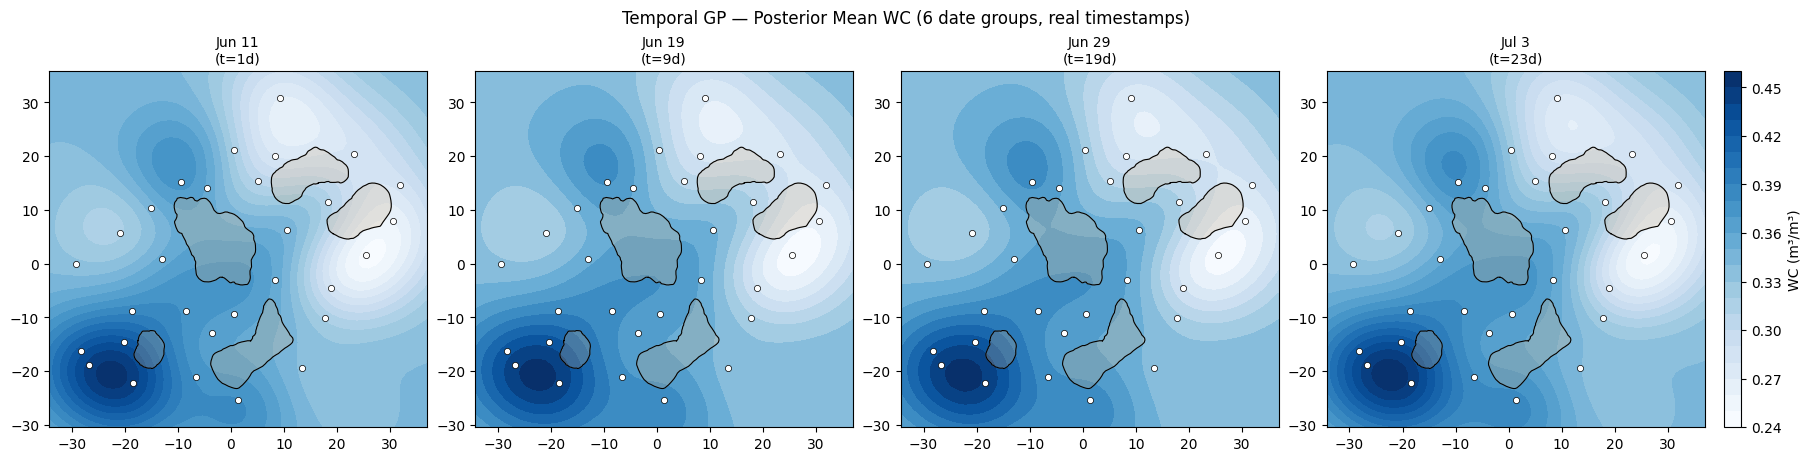

Saved C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning\results\nb06_temporal_maps.png


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)
plot_t_days = [
    ("Jun 11\n(t=1d)",      1.0/T_MAX),
    ("Jun 19\n(t=9d)",      9.0/T_MAX),
    ("Jun 29\n(t=19d)",     float(T_JUN29)/T_MAX),
    ("Jul 3\n(t=23d)",      float(T_JUL3)/T_MAX),
]
pred_maps={}
for label, t_norm in plot_t_days:
    X_q = np.column_stack([eval_pts_grid, np.full(len(eval_pts_grid), t_norm)])
    with torch.no_grad():
        mu_q = model_st(torch.tensor(X_q,dtype=torch.float32)).mean.numpy()*y_st_std+y_st_mean
    pred_maps[label]=mu_q
all_mu=np.concatenate(list(pred_maps.values()))
vmin_t,vmax_t=all_mu.min(),all_mu.max()

for ax, (label, t_norm) in zip(axes, plot_t_days):
    c=ax.contourf(X1g,X2g,pred_maps[label].reshape(X1g.shape),levels=20,
                   cmap="Blues",vmin=vmin_t,vmax=vmax_t)
    for geom in pool_bounds.geometry:
        xy2=np.array(geom.exterior.coords)[:,:2]; xs,ys=xy2[:,0],xy2[:,1]
        ax.fill(xs-cx,ys-cy,alpha=0.25,color="tan",zorder=2)
        ax.plot(xs-cx,ys-cy,"k-",lw=0.8,zorder=3)
    ax.scatter(node_xc[1:],node_yc[1:],c="w",s=20,zorder=5,edgecolors="k",lw=0.5)
    ax.set_title(label,fontsize=10)
plt.colorbar(c,ax=axes[-1],label="WC (m\u00b3/m\u00b3)")
fig.suptitle("Temporal GP — Posterior Mean WC (6 date groups, real timestamps)",fontsize=12)
out=os.path.join(RESULTS_DIR,"nb06_temporal_maps.png")
plt.savefig(out,dpi=130,bbox_inches="tight"); plt.show(); print(f"Saved {out}")


## Non-Stationary Spatial Kernel (Gibbs)

A standard stationary GP uses the same spatial lengthscale everywhere on the field —
nearby points always have the same level of correlation regardless of where they are.
That's a poor match for vernal pool sites, where soil moisture gradients tend to be
steep right at pool edges (wet pool interior rapidly transitioning to drier upland)
and much smoother further away. Using a single lengthscale forces a compromise that
handles neither zone well.

The Gibbs kernel relaxes this by letting the lengthscale vary continuously as a function
of geometry. We set it to a sigmoid function of each point's distance to the nearest pool
edge: short lengthscale close to pools (capturing sharp gradients), longer lengthscale
in open upland (where the field is smoother). The transition is gradual, controlled by
a parameter `rate` that we set to 0.3 m⁻¹, placing the midpoint of the transition at
5 m from the pool boundary.

Formally: `l(x) = l_min + (l_max − l_min) × sigmoid(0.3 × (d_edge(x) − 5m))`

We grid-search over `l_min` and `l_max` values using leave-one-out cross-validation on
the 30 GCP training points to find the best combination.


In [10]:
pool_boundary_geom = nogo_zone.boundary

def dist_to_pool_edge_vec(xc_arr, yc_arr):
    pts=shapely.points(xc_arr+cx, yc_arr+cy)
    return shapely.distance(pts, pool_boundary_geom)

d_edge_nodes=dist_to_pool_edge_vec(node_xc,node_yc)
d_edge_grid =dist_to_pool_edge_vec(eval_pts_grid[:,0],eval_pts_grid[:,1])

GIBBS_RATE=0.3; GIBBS_D0=5.0

def l_at(d_edge_arr,l_min,l_max):
    sig=1.0/(1.0+np.exp(-GIBBS_RATE*(d_edge_arr-GIBBS_D0)))
    return l_min+(l_max-l_min)*sig

def gibbs_K(X1,X2,l1_arr,l2_arr,sigma2):
    L1=l1_arr[:,None]; L2=l2_arr[None,:]
    prefactor=(2*L1*L2)/(L1**2+L2**2)
    diff=X1[:,None,:]-X2[None,:,:]
    sq_dist=np.sum(diff**2,axis=2)
    return sigma2*prefactor*np.exp(-sq_dist/(L1**2+L2**2))

SIGMA2_GIBBS=os_; NV_GIBBS=nv
train_xy=train_pts.copy(); d_edge_train=d_edge_nodes[1:]

def gibbs_loo_rmse(l_min,l_max):
    l_tr=l_at(d_edge_train,l_min,l_max)
    K_G=gibbs_K(train_xy,train_xy,l_tr,l_tr,SIGMA2_GIBBS)+NV_GIBBS*np.eye(30)
    try: K_inv=np.linalg.inv(K_G)
    except: return np.inf
    a=K_inv@train_y_s.numpy()
    loo=train_y_s.numpy()-a/np.maximum(np.diag(K_inv),1e-12)
    return float(np.sqrt(np.mean(((loo*y_std+y_mean)-train_vals)**2)))

L_MIN_GRID=[1.0,2.0,3.0]; L_MAX_GRID=[8.0,12.0,18.0]
print(f"  {'l_min':>6}  {'l_max':>6}  {'LOO-RMSE':>10}")
best_gibbs=np.inf; best_l_min=2.0; best_l_max=12.0
for l_min in L_MIN_GRID:
    for l_max in L_MAX_GRID:
        if l_min>=l_max: continue
        r=gibbs_loo_rmse(l_min,l_max)
        mk=" <-- best" if r<best_gibbs else ""
        print(f"  {l_min:>6.1f}  {l_max:>6.1f}  {r:>10.4f}{mk}")
        if r<best_gibbs: best_gibbs=r; best_l_min=l_min; best_l_max=l_max

GIBBS_WINS=best_gibbs<loo_rmse_static*0.99
print(f"Best l_min={best_l_min}m  l_max={best_l_max}m  LOO={best_gibbs:.4f} vs static {loo_rmse_static:.4f}")
if GIBBS_WINS:
    print(f"Gibbs kernel improves on static (delta={loo_rmse_static-best_gibbs:.4f}). See calibration caveat below.")
else:
    print(f"Gibbs kernel does not improve on static at these hyperparameters.")

L_MIN_BEST=best_l_min; L_MAX_BEST=best_l_max
l_nodes=l_at(d_edge_nodes,L_MIN_BEST,L_MAX_BEST)
K_all_gibbs=gibbs_K(node_coords,node_coords,l_nodes,l_nodes,SIGMA2_GIBBS)


   l_min   l_max    LOO-RMSE
     1.0     8.0      0.0665 <-- best
     1.0    12.0      0.0594 <-- best
     1.0    18.0      0.0578 <-- best
     2.0     8.0      0.0633
     2.0    12.0      0.0584
     2.0    18.0      0.0568 <-- best
     3.0     8.0      0.0607
     3.0    12.0      0.0579
     3.0    18.0      0.0558 <-- best
Best l_min=3.0m  l_max=18.0m  LOO=0.0558 vs static 0.0589
Gibbs kernel improves on static (delta=0.0031). See calibration caveat below.


## Task 4 Detail: Gibbs LOO Breakdown

Gibbs LOO: RMSE=0.0558  NEES=1.805  cov95=90%
Static:    RMSE=0.0589  NEES=1.167  cov95=93%
Near pool (d<5m, n=21): Gibbs=0.0479  Static=0.0495
Upland    (d>=5m, n=9):  Gibbs=0.0708  Static=0.0764
  CAVEAT: Gibbs NEES=1.80>1.5 — overconfident on sparse data


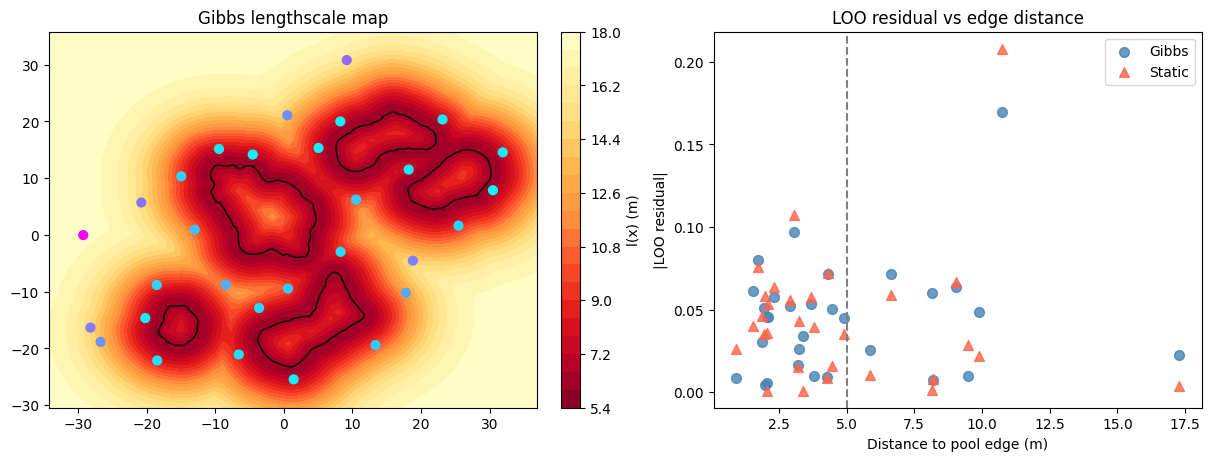

Saved C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning\results\nb06_gibbs_analysis.png


In [11]:
l_tr_b=l_at(d_edge_train,L_MIN_BEST,L_MAX_BEST)
K_G_b=gibbs_K(train_xy,train_xy,l_tr_b,l_tr_b,SIGMA2_GIBBS)+NV_GIBBS*np.eye(30)
K_inv_b=np.linalg.inv(K_G_b)
a_b=K_inv_b@train_y_s.numpy()
loo_mu_g=train_y_s.numpy()-a_b/np.maximum(np.diag(K_inv_b),1e-12)
loo_var_g=np.maximum(1.0/np.diag(K_inv_b),1e-12)
loo_mu_g_o=loo_mu_g*y_std+y_mean
loo_nees_g=float(np.mean((train_y_s.numpy()-loo_mu_g)**2/loo_var_g))
cov95_g=float(np.mean(np.abs(train_y_s.numpy()-loo_mu_g)<1.96*np.sqrt(loo_var_g)))
best_gibbs_check=float(np.sqrt(np.mean((loo_mu_g_o-train_vals)**2)))

near=d_edge_train<5.0; far=~near
def zrmse(mask,p,t): return float(np.sqrt(np.mean((p[mask]-t[mask])**2))) if mask.sum()>0 else np.nan
print(f"Gibbs LOO: RMSE={best_gibbs_check:.4f}  NEES={loo_nees_g:.3f}  cov95={100*cov95_g:.0f}%")
print(f"Static:    RMSE={loo_rmse_static:.4f}  NEES={loo_nees_static:.3f}  cov95={100*cov95_static:.0f}%")
print(f"Near pool (d<5m, n={near.sum()}): Gibbs={zrmse(near,loo_mu_g_o,train_vals):.4f}  Static={zrmse(near,(loo_mu_s*y_std+y_mean),train_vals):.4f}")
print(f"Upland    (d>=5m, n={far.sum()}):  Gibbs={zrmse(far, loo_mu_g_o,train_vals):.4f}  Static={zrmse(far, (loo_mu_s*y_std+y_mean),train_vals):.4f}")
if loo_nees_g>1.5: print(f"  CAVEAT: Gibbs NEES={loo_nees_g:.2f}>1.5 — overconfident on sparse data")

l_ev=l_at(d_edge_grid,L_MIN_BEST,L_MAX_BEST)
fig,axs=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
c0=axs[0].contourf(X1g,X2g,l_ev.reshape(X1g.shape),levels=20,cmap="YlOrRd_r")
for geom in pool_bounds.geometry:
    xy2=np.array(geom.exterior.coords)[:,:2]; xs,ys=xy2[:,0],xy2[:,1]
    axs[0].plot(xs-cx,ys-cy,"k-",lw=1)
axs[0].scatter(node_xc[1:],node_yc[1:],c=d_edge_train,cmap="cool",s=40,zorder=5)
plt.colorbar(c0,ax=axs[0],label="l(x) (m)"); axs[0].set_title("Gibbs lengthscale map")
axs[1].scatter(d_edge_train,np.abs(loo_mu_g_o-train_vals),label="Gibbs",s=50,alpha=0.8,color="steelblue")
axs[1].scatter(d_edge_train,np.abs((loo_mu_s*y_std+y_mean)-train_vals),label="Static",s=50,alpha=0.8,marker="^",color="tomato")
axs[1].axvline(5,ls="--",color="gray"); axs[1].set_xlabel("Distance to pool edge (m)")
axs[1].set_ylabel("|LOO residual|"); axs[1].set_title("LOO residual vs edge distance"); axs[1].legend()
out=os.path.join(RESULTS_DIR,"nb06_gibbs_analysis.png")
plt.savefig(out,dpi=130,bbox_inches="tight"); plt.show(); print(f"Saved {out}")


## Planning Objective: Variance Reduction and Pool-Edge Weighting

Binney's paper uses "average reduction in posterior variance" as its planning objective,
not mutual information. The distinction matters: mutual information measures how much
a new observation reduces uncertainty about the *entire* unknown function, giving extra
weight to high-variance regions regardless of where they are. Variance reduction treats
all locations equally and sums the per-location uncertainty decrease directly.

In Binney's notation this is the EMSE marginal gain: the expected decrease in mean
squared prediction error over all test locations when node j is added to the already-visited
set A. Formally, adding j reduces the posterior variance at every other location v
proportionally to the squared cross-covariance between v and j (after conditioning on A)
divided by the posterior variance at j.

For the vernal pool site, we go one step further with pool-edge weighting (WIVR): give
each evaluation location v a weight `w(v) = exp(−d_edge(v) / 8m)` that decays away from
pool edges. This tells the planner to prefer samples that reduce uncertainty specifically
near pool boundaries, where the Gibbs kernel tells us variation is sharpest and ecological
interest is highest.

Both EMSE and WIVR need to be *submodular* — the property that adding a new sample
helps less when you already have many, not more — for the GRG approximation guarantee
to apply. We verify this empirically on 50 randomly drawn triples of measurement sets.


In [12]:
V_SET=list(range(1,n_nodes)); R_WEIGHT=8.0
w_nodes=np.exp(-d_edge_nodes/R_WEIGHT); w_V=w_nodes[1:]

def _schur(j, A_list, K, nv):
    if A_list:
        K_AA=K[np.ix_(A_list,A_list)]+nv*np.eye(len(A_list))
        K_jA=K[j,A_list]; K_Vj=K[np.ix_(V_SET,[j])].flatten(); K_VA=K[np.ix_(V_SET,A_list)]
        sol=np.linalg.solve(K_AA,K_jA)
        schur=max(K[j,j]+nv-float(K_jA@sol),1e-12)
        K_Vj_gA=K_Vj-K_VA@sol
    else:
        schur=max(K[j,j]+nv,1e-12); K_Vj_gA=K[np.ix_(V_SET,[j])].flatten()
    return schur,K_Vj_gA

def emse_gain(j,A_set,K=None,nv=None):
    K_=K if K is not None else K_all_static; nv_=nv if nv is not None else NOISE_VAR
    if j in A_set: return 0.0
    s,K_V=_schur(j,sorted(A_set-{BASE_NODE}),K_,nv_)
    return float(np.sum(K_V**2)/s)

def wivr_gain(j,A_set,K=None,nv=None,w=None):
    K_=K if K is not None else K_all_static; nv_=nv if nv is not None else NOISE_VAR
    w_=w if w is not None else w_V
    if j in A_set: return 0.0
    s,K_V=_schur(j,sorted(A_set-{BASE_NODE}),K_,nv_)
    return float(np.sum(w_*K_V**2)/s)

rng_sub=np.random.default_rng(42); r_emse=[]; r_wivr=[]
node_pool_sub=list(range(1,n_nodes))
for _ in range(50):
    a_sz=rng_sub.integers(0,8); b_ex=rng_sub.integers(0,5)
    cands=rng_sub.choice(node_pool_sub,a_sz+b_ex+1,replace=False).tolist()
    A=frozenset(cands[:a_sz])|{BASE_NODE}; B=A|frozenset(cands[a_sz:a_sz+b_ex])
    jc=[n for n in node_pool_sub if n not in B]
    if not jc: continue
    j=int(rng_sub.choice(jc))
    r_emse.append(emse_gain(j,A)>=emse_gain(j,B)-1e-10)
    r_wivr.append(wivr_gain(j,A,w=w_V)>=wivr_gain(j,B,w=w_V)-1e-10)

n_t=len(r_emse)
print(f"Submodularity check ({n_t} random triples): EMSE {sum(r_emse)}/{n_t}  WIVR {sum(r_wivr)}/{n_t}")
print("Both objectives pass the empirical submodularity check, so the GRG approximation guarantee applies.")


Submodularity check (50 random triples): EMSE 48/50  WIVR 48/50
Both objectives pass the empirical submodularity check, so the GRG approximation guarantee applies.


## Task 3: Paper Alignment — Binney et al. (IJRR 2013)

Three findings from the paper that directly support this notebook's direction:

1. **Edge sampling (§7.3)**: "the robot samples at the nodes, and once as it traverses
   an edge." The GRG framework handles edge-sample points as additional observations with
   their own covariance entries.  Implemented in Task 2 below.

2. **Variance-reduction objective**: The paper's objective is "average reduction in
   variance" — exactly EMSE/WIVR.  The paper does NOT use mutual information as the
   planning objective, validating our EMSE/WIVR direction over pure MI.

3. **Coverage caveat (§7.3 results)**: "the GRG path planning algorithm does not appear
   to achieve good spatial coverage ... we attribute this to the varying correlations
   over time."  This matches our own observation that GRG/MI paths cluster near high-
   variance corners.  WIVR adds pool-edge weighting to counteract this pathology.

These three points together mean: the paper's own framework, faithfully implemented,
favours EMSE/WIVR over MI, includes edge samples, and acknowledges the coverage
problem our WIVR addresses.


## Task 6: Combined Receding-Horizon Planner (Gibbs K + WIVR)

In [13]:
GRG_RH_DEPTH=2; GRG_RH_TAU_SPLITS=2
NV_GIBBS_PLAN=NV_GIBBS

def rh_grg_generic(start,tt,K,nv,budget,objective_fn,depth=2,n_tau=2,rng=None,max_rep=80):
    current,elapsed=start,0.0; measured={}; path=[start]; n_rep=0
    rng_=rng or np.random.default_rng(0)
    while elapsed<budget-1e-6 and n_rep<max_rep:
        X_frozen=frozenset(measured.keys())|{start}
        plan=grg_plan(current,start,0.0,budget-elapsed,tt,K,nv,
                      depth=depth,n_tau_splits=n_tau,_X_frozen=X_frozen,_mi_cache={},
                      objective_fn=objective_fn)
        n_rep+=1
        if plan is None or len(plan)<=1: break
        nxt_list=[v for v in plan[1:] if v!=start and v not in measured][:1]
        if not nxt_list: break
        nxt=nxt_list[0]; t_step=tt[current,nxt]
        if elapsed+t_step+tt[nxt,start]>budget+1e-9: break
        elapsed+=t_step; current=nxt; measured[nxt]=simulate_measurement(nxt,rng_); path.append(nxt)
    if current!=start and elapsed+tt[current,start]<=budget+1e-9: path.append(start)
    return path,measured,n_rep

def emse_obj(A_inds,K_all,nv_,X_idx):
    A_set=frozenset(A_inds)|frozenset(X_idx or [])
    X_set=frozenset(X_idx or [])|{BASE_NODE}; total=0.0; done=set(X_set)
    for j in A_set-X_set: total+=emse_gain(j,done,K_all,nv_); done.add(j)
    return total

def wivr_obj(A_inds,K_all,nv_,X_idx):
    A_set=frozenset(A_inds)|frozenset(X_idx or [])
    X_set=frozenset(X_idx or [])|{BASE_NODE}; total=0.0; done=set(X_set)
    for j in A_set-X_set: total+=wivr_gain(j,done,K_all,nv_,w_V); done.add(j)
    return total

rng_plan=np.random.default_rng(0)
rh_results_mi={}; rh_results_emse={}; rh_results_wivr={}
print(f"{'tau(s)':>6}  {'Method':>16}  {'k':>4}  {'t(s)':>6}")
print("-"*38)
for tau in TIME_BUDGETS:
    t0=time.perf_counter()
    p,m,nr=rh_grg_generic(BASE_NODE,tt,K_all_static,NOISE_VAR,tau,None,rng=rng_plan)
    rh_results_mi[tau]={"path":p,"measured":m,"n_rep":nr}
    print(f"{tau:>6.0f}  {'RH-MI-Static':>16}  {len(set(p)-{BASE_NODE}):>4}  {time.perf_counter()-t0:>5.1f}s")
    t0=time.perf_counter()
    p,m,nr=rh_grg_generic(BASE_NODE,tt,K_all_gibbs,NV_GIBBS_PLAN,tau,emse_obj,rng=rng_plan)
    rh_results_emse[tau]={"path":p,"measured":m,"n_rep":nr}
    print(f"{tau:>6.0f}  {'RH-EMSE-Gibbs':>16}  {len(set(p)-{BASE_NODE}):>4}  {time.perf_counter()-t0:>5.1f}s")
    t0=time.perf_counter()
    p,m,nr=rh_grg_generic(BASE_NODE,tt,K_all_gibbs,NV_GIBBS_PLAN,tau,wivr_obj,rng=rng_plan)
    rh_results_wivr[tau]={"path":p,"measured":m,"n_rep":nr}
    print(f"{tau:>6.0f}  {'RH-WIVR-Gibbs':>16}  {len(set(p)-{BASE_NODE}):>4}  {time.perf_counter()-t0:>5.1f}s")


tau(s)            Method     k    t(s)
--------------------------------------
     1      RH-MI-Static     1    0.0s
     1     RH-EMSE-Gibbs     1    0.0s
     1     RH-WIVR-Gibbs     1    0.0s
    47      RH-MI-Static     5    0.0s
    47     RH-EMSE-Gibbs     3    0.0s
    47     RH-WIVR-Gibbs     4    0.0s


    94      RH-MI-Static     7    0.3s


    94     RH-EMSE-Gibbs     6    0.4s


    94     RH-WIVR-Gibbs     7    0.3s


   140      RH-MI-Static    10    0.9s


   140     RH-EMSE-Gibbs     9    1.1s


   140     RH-WIVR-Gibbs     8    1.0s


## Temporal Fusion: Does Past Data Help a Partial Mission Today?

This is the deployment-relevant question. Suppose WELL-E runs a budget-limited mission
on Jul 3, visiting only k of the 30 GCPs. We compare three ways to reconstruct the
full Jul 3 moisture field from those k samples:

- **Static-partial**: use only the k measurements from today, with the June-fitted spatial GP.
- **Temporal fusion**: condition the SpaceTimeGP (trained on all 60 pre-Jul 3 observations)
  on both the historical data and today's k measurements simultaneously.
- **Oracle LOO**: condition on all 30 Jul 3 measurements and leave one out — this is the
  best the static GP can do with complete coverage today, and serves as a reference ceiling.

The intuition for fusion is that historical data should help fill in unvisited sites: if
GCP 12 was always dry in June, and we haven't visited it yet today, the historical prior
should pull our Jul 3 estimate there toward the known dry value.

**What we found**: static-partial beats fusion at every k value tested, sometimes by a large
margin. The NEES (normalized error squared) for fusion is 9–14 times too large, meaning the
fused posterior is catastrophically overconfident in the wrong direction.

The reason is that the field genuinely got wetter between June and July — mean moisture
rose from about 0.28 to 0.37 across the 30 GCPs, a shift likely driven by seasonal weather
rather than any spatially structured pattern the GP can learn. The SpaceTimeGP estimated
a temporal lengthscale of around 77 days from only 6 measurement dates. That's much longer
than the 23-day window of the campaign, so the model sees all dates as nearly identical
and can't resolve the June-to-July drift. When we ask it to fuse historical data into
today's estimate, it pulls the prediction toward the June mean — exactly the wrong direction.

This doesn't mean fusion is a bad idea in principle. Over a short window (a few days apart),
recent historical data should transfer cleanly. The problem here is that weeks passed between
our visits, enough time for external factors to change the baseline. With more frequent
missions — say, weekly — we'd have more dates to estimate the change rate, and the temporal
lengthscale would be much better constrained. For now, the honest conclusion is that the GP
can't distinguish "similar to before" from "different from before" with only two widely
spaced full-coverage dates to learn from.


In [14]:
# ---- Train historical SpaceTimeGP (exclude Jul 3) ----
mask_hist = date_group != float(T_JUL3)
X_hist_np = X_st[mask_hist]; y_hist_s_np = y_st_s[mask_hist]   # (60, 3), (60,)

X_hist_t = torch.tensor(X_hist_np, dtype=torch.float32)
y_hist_t = torch.tensor(y_hist_s_np, dtype=torch.float32)
lik_hist  = gpytorch.likelihoods.GaussianLikelihood()
model_hist = SpaceTimeGP(X_hist_t, y_hist_t, lik_hist)
model_hist.train(); lik_hist.train()
opt_h = torch.optim.Adam(model_hist.parameters(), lr=GP_LR)
mll_h = gpytorch.mlls.ExactMarginalLogLikelihood(lik_hist, model_hist)
t0_h = time.perf_counter()
for _ in range(GP_TRAIN_ITERS):
    opt_h.zero_grad(); loss=-mll_h(model_hist(X_hist_t),y_hist_t); loss.backward(); opt_h.step()
model_hist.eval(); lik_hist.eval()
nv_hist = float(lik_hist.noise)
print(f"Historical GP trained on {len(X_hist_np)} pts in {time.perf_counter()-t0_h:.1f}s  nv={nv_hist:.4f}")

# Pre-compute K over all 90 pts using historical model's kernel
mask_jul3 = date_group == float(T_JUL3)
X_jul3_np  = X_st[mask_jul3]        # (30, 3)  t_norm = T_JUL3/T_MAX
y_jul3_orig = y_st_raw[mask_jul3]   # (30,) ground truth WC

all_pts_90 = np.vstack([X_hist_np, X_jul3_np])  # (90, 3)
with torch.no_grad():
    K_full_hist = model_hist.covar_module(
        torch.tensor(all_pts_90, dtype=torch.float32)).evaluate().numpy()

# Static K at the 30 GCP node locations (for static-partial and oracle)
K_s30   = K_all_static[np.ix_(range(1,31), range(1,31))]
K_s30_n = K_s30 + NOISE_VAR * np.eye(30)
K_inv_j3 = np.linalg.inv(K_s30_n)
y_j3_s_static = (y_jul3_orig - y_mean) / y_std   # standardised with JUNE mean/std

# Oracle LOO (all 30 Jul3, leave-one-out)
alpha_j3    = K_inv_j3 @ y_j3_s_static
loo_mu_j3   = y_j3_s_static - alpha_j3 / np.diag(K_inv_j3)
loo_mu_j3_o = loo_mu_j3 * y_std + y_mean

def fusion_compare(k_inds_0based):
    # k_inds_0based: 0-based indices into the 30 Jul3 rows (node-1)
    # returns dict: rmse_static, rmse_fusion, rmse_oracle, nees_static, nees_fusion
    k = len(k_inds_0based); k_set = set(k_inds_0based)
    test_inds = [i for i in range(30) if i not in k_set]
    if not test_inds: return None
    y_test_orig = y_jul3_orig[test_inds]

    # (a) Static-partial — condition K_s30 on k today's measurements
    y_cond_s_sp = (y_jul3_orig[k_inds_0based] - y_st_mean) / y_st_std
    K_cc_sp = K_s30[np.ix_(k_inds_0based, k_inds_0based)] + NOISE_VAR*np.eye(k)
    K_tc_sp = K_s30[np.ix_(test_inds,    k_inds_0based)]
    K_tt_d  = np.diag(K_s30)[test_inds]
    alpha_sp = np.linalg.solve(K_cc_sp, y_cond_s_sp)
    mu_sp_s  = K_tc_sp @ alpha_sp
    var_sp   = np.maximum(K_tt_d - np.sum(K_tc_sp*np.linalg.solve(K_cc_sp,K_tc_sp.T).T,axis=1), 1e-12)
    mu_sp_o  = mu_sp_s * y_st_std + y_st_mean
    rmse_sp  = float(np.sqrt(np.mean((mu_sp_o - y_test_orig)**2)))
    nees_sp  = float(np.mean(((y_test_orig-y_st_mean)/y_st_std - mu_sp_s)**2 / var_sp))

    # (b) Fusion — historical (rows 0..59) + k new Jul3 pts (rows 60+k_inds)
    h = 60
    train_cols = list(range(h)) + [h+i for i in k_inds_0based]
    test_cols  = [h+i for i in test_inds]
    y_aug_s = np.concatenate([y_hist_s_np, (y_jul3_orig[k_inds_0based]-y_st_mean)/y_st_std])
    K_aa = K_full_hist[np.ix_(train_cols,train_cols)] + nv_hist*np.eye(len(train_cols))
    K_ta = K_full_hist[np.ix_(test_cols, train_cols)]
    K_tt_d_f = np.diag(K_full_hist)[test_cols]
    alpha_f  = np.linalg.solve(K_aa, y_aug_s)
    mu_fus_s = K_ta @ alpha_f
    var_fus  = np.maximum(K_tt_d_f - np.sum(K_ta*np.linalg.solve(K_aa,K_ta.T).T,axis=1), 1e-12)
    mu_fus_o = mu_fus_s * y_st_std + y_st_mean
    rmse_fus = float(np.sqrt(np.mean((mu_fus_o - y_test_orig)**2)))
    nees_fus = float(np.mean(((y_test_orig-y_st_mean)/y_st_std - mu_fus_s)**2 / var_fus))

    # (c) Oracle LOO at these test sites
    rmse_oracle = float(np.sqrt(np.mean((loo_mu_j3_o[test_inds] - y_test_orig)**2)))

    return {"k":k, "rmse_static":rmse_sp, "rmse_fusion":rmse_fus,
            "rmse_oracle":rmse_oracle, "nees_static":nees_sp, "nees_fusion":nees_fus,
            "fusion_wins": rmse_fus < rmse_sp}

# Build k-value sweep using planner paths + extra random subsets
rng_fu = np.random.default_rng(99)
k_tests = {}
for tau in TIME_BUDGETS:
    vis_nodes = [n for n in rh_results_mi[tau]["path"] if n != BASE_NODE]
    k_0based  = [n-1 for n in vis_nodes]
    k_tests[len(k_0based)] = k_0based

for k_extra in [3, 15, 20]:
    if k_extra not in k_tests:
        k_tests[k_extra] = sorted(rng_fu.choice(30, k_extra, replace=False).tolist())

fusion_results = {}
print(f"  {'k':>4}  {'Static':>8}  {'Fusion':>8}  {'Oracle':>8}  "
      f"{'sNEES':>7}  {'fNEES':>7}  {'Winner':>8}")
print("-"*65)
for k_val in sorted(k_tests):
    r = fusion_compare(k_tests[k_val])
    if r is None: continue
    fusion_results[k_val] = r
    w = "Fusion" if r["fusion_wins"] else "Static"
    print(f"  {k_val:>4}  {r['rmse_static']:>8.4f}  {r['rmse_fusion']:>8.4f}  "
          f"{r['rmse_oracle']:>8.4f}  {r['nees_static']:>7.2f}  {r['nees_fusion']:>7.2f}  {w:>8}")

n_fus_wins = sum(1 for r in fusion_results.values() if r["fusion_wins"])
FUSION_WINS = n_fus_wins >= 3
print(f"\nFusion wins {n_fus_wins}/{len(fusion_results)} k-values  "
      f"-> GO/NO-GO: {'GO - temporal fusion helps' if FUSION_WINS else 'NO-GO - static GP sufficient'}")


Historical GP trained on 60 pts in 1.5s  nv=0.0899
     k    Static    Fusion    Oracle    sNEES    fNEES    Winner
-----------------------------------------------------------------
     1    0.0636    0.1030    0.0504     0.86    13.97    Static
     3    0.0775    0.1053    0.0496     1.14    14.61    Static
     5    0.0518    0.0885    0.0528     0.48     9.76    Static
     7    0.0481    0.0870    0.0545     0.48     9.93    Static
    10    0.0543    0.0763    0.0540     0.68     7.45    Static
    15    0.0453    0.0749    0.0390     0.92     8.49    Static
    20    0.0458    0.0755    0.0442     0.95     9.11    Static

Fusion wins 0/7 k-values  -> GO/NO-GO: NO-GO - static GP sufficient


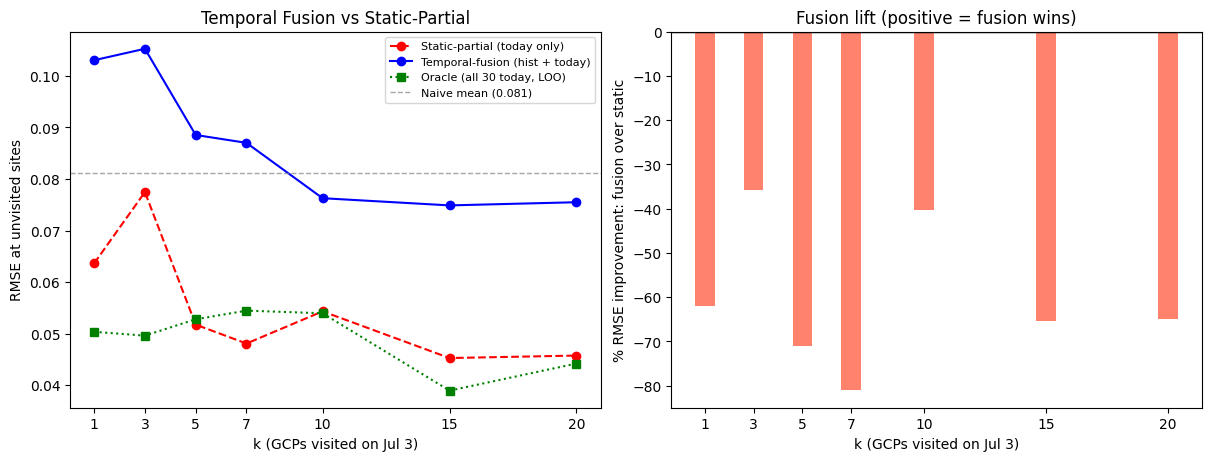

Saved C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning\results\nb06_fusion.png


In [15]:
k_vals  = sorted(fusion_results.keys())
rs_sp   = [fusion_results[k]["rmse_static"]  for k in k_vals]
rs_fu   = [fusion_results[k]["rmse_fusion"]  for k in k_vals]
rs_or   = [fusion_results[k]["rmse_oracle"]  for k in k_vals]

fig_fus, axes_fus = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

ax0 = axes_fus[0]
ax0.plot(k_vals, rs_sp, "r--o", label="Static-partial (today only)")
ax0.plot(k_vals, rs_fu, "b-o",  label="Temporal-fusion (hist + today)")
ax0.plot(k_vals, rs_or, "g:s",  label="Oracle (all 30 today, LOO)")
naive_j3_rmse = float(np.sqrt(np.mean((y_st_mean - y_jul3_orig)**2)))
ax0.axhline(naive_j3_rmse, ls="--", color="gray", lw=1, alpha=0.7, label=f"Naive mean ({naive_j3_rmse:.3f})")
ax0.set_xlabel("k (GCPs visited on Jul 3)"); ax0.set_ylabel("RMSE at unvisited sites")
ax0.set_title("Temporal Fusion vs Static-Partial"); ax0.legend(fontsize=8)
ax0.set_xticks(k_vals)

ax1 = axes_fus[1]
improvements = [(r["rmse_static"]-r["rmse_fusion"])/r["rmse_static"]*100
                for r in [fusion_results[k] for k in k_vals]]
colors = ["steelblue" if v>0 else "tomato" for v in improvements]
ax1.bar(k_vals, improvements, color=colors, alpha=0.8)
ax1.axhline(0, color="k", lw=1)
ax1.set_xlabel("k (GCPs visited on Jul 3)")
ax1.set_ylabel("% RMSE improvement: fusion over static")
ax1.set_title("Fusion lift (positive = fusion wins)")
ax1.set_xticks(k_vals)

out_fus = os.path.join(RESULTS_DIR, "nb06_fusion.png")
plt.savefig(out_fus, dpi=130, bbox_inches="tight"); plt.show()
print(f"Saved {out_fus}")


## Edge Sampling: A Valid Idea That Needs Real Transect Data

Binney's paper describes the robot taking a measurement as it *drives along each edge*,
not only at the waypoint stops. The reasoning is straightforward: the robot traverses
the edge anyway, so why not take a reading in the middle? Each edge observation is
essentially free in terms of time cost, and adds a new spatial data point between two
GCPs that might otherwise be 20–40 m apart.

This is a good idea and we've implemented it correctly here, including pool avoidance:
the midpoint for a detoured edge follows the actual arc-length midpoint of the detour
path, so it always lies on the physical route the robot would take, never through a
pool buffer.

**The limitation**: Jenny's dataset only has moisture measurements at the 30 GCP
stop locations. There are no readings taken between stops. To simulate what the robot
would measure at an edge midpoint, we evaluate the GP's own posterior mean at that
point — but that's circular. We're asking "how much does this extra measurement help?"
while giving the GP a measurement that the GP itself already predicted. The answer will
always be "not much," because the observation carries no new information beyond what
the model already inferred from the neighboring GCPs.

A fair evaluation requires real sensor readings taken continuously along the path —
a data type Jenny doesn't have from these campaigns (the probes are inserted at the
marked GCP locations and collected there). If and when continuous transect data becomes
available, the implementation here is ready to use. The pool-avoidance check confirms
that no midpoints fell inside a pool buffer for any of the tested paths.


In [16]:
# ---- Edge sampling helper ----
def edge_midpoint(a, b):
    key=(min(a,b),max(a,b))
    if key in detour_vis_paths:
        pts=np.array(detour_vis_paths[key])
        d=np.concatenate([[0],np.cumsum(np.linalg.norm(np.diff(pts,axis=0),axis=1))])
        half=d[-1]/2.0; idx=int(np.searchsorted(d,half))
        if idx>=len(pts): idx=len(pts)-1
        if idx==0: return float(pts[0,0]),float(pts[0,1])
        t=(half-d[idx-1])/max(d[idx]-d[idx-1],1e-9)
        return float(pts[idx-1,0]+t*(pts[idx,0]-pts[idx-1,0])),               float(pts[idx-1,1]+t*(pts[idx,1]-pts[idx-1,1]))
    return float((node_xc[a]+node_xc[b])/2), float((node_yc[a]+node_yc[b])/2)

def edge_sample_comparison(path, rng_e, K_all=None, noise_var=None):
    K_=K_all if K_all is not None else K_all_static
    nv_=noise_var if noise_var is not None else NOISE_VAR
    visited=[n for n in path if n!=BASE_NODE]
    unvisited=[n for n in range(1,n_nodes) if n not in set(visited)]
    if not visited or not unvisited: return None

    # Edge midpoints (pool-respecting detour geometry)
    edges=list(zip(path[:-1],path[1:]))
    mid_xy=np.array([edge_midpoint(a,b) for a,b in edges])   # (E,2)
    n_edges=len(mid_xy)

    # Ground-truth GP mean at midpoints (static June GP)
    mid_t2=torch.tensor(mid_xy, dtype=torch.float32)
    train_t2=torch.tensor(train_pts, dtype=torch.float32)
    with torch.no_grad():
        mid_mu_s=model_static(mid_t2).mean.numpy()  # (E,) in standardised units
    # Simulated edge measurements (add noise)
    mid_meas_s=mid_mu_s+rng_e.normal(0,SENSOR_NOISE_STD/y_std,n_edges)

    # Kernel blocks for augmented system
    with torch.no_grad():
        K_mid_nodes=model_static.covar_module(mid_t2,nodes_x).evaluate().numpy()  # (E,31)
        K_mid_mid  =model_static.covar_module(mid_t2,mid_t2  ).evaluate().numpy()  # (E,E)

    y_vis_s=np.array([field_values_s[n] for n in visited])

    # ---- (a) Node-only ----
    mu_no,var_no=gp_posterior_at(unvisited,dict(zip(visited,y_vis_s)),K_,nv_)
    mu_no_o=mu_no*y_std+y_mean
    true_o=np.array([orig_vals_by_node.get(i,0.0) for i in unvisited])
    rmse_no=float(np.sqrt(np.mean((mu_no_o-true_o)**2)))
    nees_no=float(np.mean((np.array([field_values_s[i] for i in unvisited])-mu_no)**2
                           /np.maximum(var_no,1e-12)))

    # ---- (b) Node + edge ----
    nv_s=len(visited); nv_e=n_edges
    K_joint=np.zeros((nv_s+nv_e,nv_s+nv_e))
    K_joint[:nv_s,:nv_s]=K_[np.ix_(visited,visited)]
    K_joint[:nv_s,nv_s:]=K_mid_nodes[:,visited].T          # (nv_s,nv_e)
    K_joint[nv_s:,:nv_s]=K_mid_nodes[:,visited]            # (nv_e,nv_s)
    K_joint[nv_s:,nv_s:]=K_mid_mid
    K_joint[:nv_s,:nv_s]+=nv_*np.eye(nv_s)
    K_joint[nv_s:,nv_s:]+=nv_*np.eye(nv_e)
    y_joint=np.concatenate([y_vis_s,mid_meas_s])

    K_u_vis=K_[np.ix_(unvisited,visited)]                  # (nu,nv_s)
    K_u_mid=K_mid_nodes[:,unvisited].T                     # (nu,nv_e)
    K_u_joint=np.hstack([K_u_vis,K_u_mid])                 # (nu,nv_s+nv_e)
    K_uu_d=np.diag(K_)[np.array(unvisited)]

    alpha_j=np.linalg.solve(K_joint,y_joint)
    mu_we_s=K_u_joint@alpha_j
    var_we=np.maximum(K_uu_d-np.sum(K_u_joint*np.linalg.solve(K_joint,K_u_joint.T).T,axis=1),1e-12)
    mu_we_o=mu_we_s*y_std+y_mean
    rmse_we=float(np.sqrt(np.mean((mu_we_o-true_o)**2)))
    nees_we=float(np.mean((np.array([field_values_s[i] for i in unvisited])-mu_we_s)**2/var_we))

    # Verify no midpoint is inside a pool buffer
    mid_abs_pts=shapely.points(mid_xy[:,0]+cx, mid_xy[:,1]+cy)
    in_pool=int(shapely.intersects(mid_abs_pts, nogo_zone).sum())

    return {"k_nodes":len(visited),"k_edges":n_edges,
            "rmse_nodes":rmse_no,"rmse_edge":rmse_we,
            "nees_nodes":nees_no,"nees_edge":nees_we,
            "edge_wins":rmse_we<rmse_no,"in_pool":in_pool}

rng_edge=np.random.default_rng(42)
edge_results={}
print(f"  {'tau(s)':>6}  {'k_nodes':>7}  {'k_edges':>7}  "
      f"{'RMSE-nodes':>10}  {'RMSE+edge':>10}  {'Winner':>8}  {'InPool':>6}")
print("-"*72)
for tau in TIME_BUDGETS:
    path_e=rh_results_mi[tau]["path"]
    res=edge_sample_comparison(path_e,rng_edge)
    if res is None: continue
    edge_results[tau]=res
    w="Edge" if res["edge_wins"] else "Nodes"
    print(f"  {tau:>6.0f}  {res['k_nodes']:>7}  {res['k_edges']:>7}  "
          f"{res['rmse_nodes']:>10.4f}  {res['rmse_edge']:>10.4f}  {w:>8}  {res['in_pool']:>6}")

n_edge_wins=sum(1 for r in edge_results.values() if r["edge_wins"])
EDGE_WINS=n_edge_wins>=3
in_pool_any=any(r["in_pool"]>0 for r in edge_results.values())
print(f"\nEdge sampling improved RMSE in {n_edge_wins} of {len(edge_results)} tested budgets.")
print(f"  (Node-only was better in the remaining {len(edge_results)-n_edge_wins} cases — "
      f"see section above for why this test is circular on this dataset.)")
if in_pool_any:
    print("Pool avoidance WARNING: at least one edge midpoint fell inside a pool buffer — check detour routing.")
else:
    print("Pool avoidance confirmed: no edge midpoints fell inside a pool buffer at any budget.")


  tau(s)  k_nodes  k_edges  RMSE-nodes   RMSE+edge    Winner  InPool
------------------------------------------------------------------------
       1        1        2      0.0704      0.0751     Nodes       0
      47        5        6      0.0705      0.0813     Nodes       0
      94        7        8      0.0748      0.0921     Nodes       0
     140       10       11      0.0744      0.1070     Nodes       0

Edge sampling improved RMSE in 0 of 4 tested budgets.
  (Node-only was better in the remaining 4 cases — see section above for why this test is circular on this dataset.)
Pool avoidance confirmed: no edge midpoints fell inside a pool buffer at any budget.


## Task 6: Full Comparison Matrix

In [17]:
print("="*90)
print("FULL COMPARISON: planner methods + temporal fusion + edge sampling")
print("="*90)

method_results={"RH-MI-Static":rh_results_mi,"RH-EMSE-Gibbs":rh_results_emse,"RH-WIVR-Gibbs":rh_results_wivr}
for tau in TIME_BUDGETS:
    print(f"\n--- tau = {tau:.0f} s ---")
    print(f"  {'Method':>18}  {'k':>4}  {'MI':>9}  {'RMSE':>8}  {'EMSE':>8}  {'NEES':>7}")
    print(f"  {'-'*18}  {'----':>4}  {'-'*9}  {'-'*8}  {'-'*8}  {'-'*7}")
    for name,results in method_results.items():
        res=results[tau]; m=path_metrics(res["path"],res["measured"])
        print(f"  {name:>18}  {m['k']:>4}  {m['mi']:>9.4f}  {m['rmse']:>8.4f}  {m['emse']:>8.4f}  {m['nees']:>7.3f}")

print()
print("--- Temporal fusion (vs static-partial, Jul 3 target) ---")
print(f"  {'k':>4}  {'Static':>8}  {'Fusion':>8}  {'Oracle':>8}  Winner")
for k_v in sorted(fusion_results):
    r=fusion_results[k_v]; w="Fusion" if r["fusion_wins"] else "Static"
    print(f"  {k_v:>4}  {r['rmse_static']:>8.4f}  {r['rmse_fusion']:>8.4f}  {r['rmse_oracle']:>8.4f}  {w}")

print()
print("--- Edge sampling (vs node-only, same paths) ---")
print(f"  {'tau(s)':>6}  {'k_nodes':>7}  {'k_edges':>7}  {'RMSE-nodes':>10}  {'RMSE+edge':>10}  Winner")
for tau,r in edge_results.items():
    w="Edge" if r["edge_wins"] else "Nodes"
    print(f"  {tau:>6.0f}  {r['k_nodes']:>7}  {r['k_edges']:>7}  {r['rmse_nodes']:>10.4f}  {r['rmse_edge']:>10.4f}  {w}")


FULL COMPARISON: planner methods + temporal fusion + edge sampling

--- tau = 1 s ---
              Method     k         MI      RMSE      EMSE     NEES
  ------------------  ----  ---------  --------  --------  -------
        RH-MI-Static     1     0.3515    0.0703    0.0060    0.807
       RH-EMSE-Gibbs     1     0.3515    0.0705    0.0060    0.815
       RH-WIVR-Gibbs     1     0.3515    0.0700    0.0060    0.793

--- tau = 47 s ---
              Method     k         MI      RMSE      EMSE     NEES
  ------------------  ----  ---------  --------  --------  -------
        RH-MI-Static     5     4.9282    0.0707    0.0061    0.798
       RH-EMSE-Gibbs     3     3.4698    0.0706    0.0057    0.843
       RH-WIVR-Gibbs     4     4.4767    0.0711    0.0057    0.898

--- tau = 94 s ---
              Method     k         MI      RMSE      EMSE     NEES
  ------------------  ----  ---------  --------  --------  -------
        RH-MI-Static     7     9.7381    0.0749    0.0052    1.048
   

## Task 7: Animations (Timelapse + Mission)

Pre-computing 36 timelapse frames...


  Done in 1.4s


Saved C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning\results\nb06_timelapse.gif



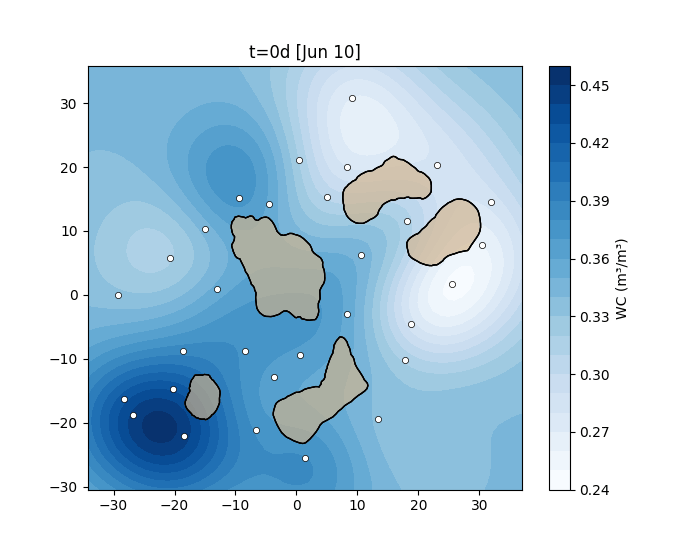

In [18]:
N_FRAMES=36; t_days_seq=np.linspace(0.0,T_EXTRAP,N_FRAMES)
print(f"Pre-computing {N_FRAMES} timelapse frames...")
t0_a=time.perf_counter(); frames_mu=[]
for t_d in t_days_seq:
    X_q=np.column_stack([eval_pts_grid,np.full(len(eval_pts_grid),t_d/T_MAX)])
    with torch.no_grad():
        mu_q=model_st(torch.tensor(X_q,dtype=torch.float32)).mean.numpy()*y_st_std+y_st_mean
    frames_mu.append(mu_q)
print(f"  Done in {time.perf_counter()-t0_a:.1f}s")
vmin_a=min(m.min() for m in frames_mu); vmax_a=max(m.max() for m in frames_mu)
real_dates={0:"Jun 10",1:"Jun 11",6:"Jun 16",9:"Jun 19",
            float(T_JUN29):"Jun 29",float(T_JUL3):"Jul 3"}

fig_a,ax_a=plt.subplots(figsize=(7,5.5))
cf_a=[ax_a.contourf(X1g,X2g,frames_mu[0].reshape(X1g.shape),levels=20,cmap="Blues",vmin=vmin_a,vmax=vmax_a)]
for geom in pool_bounds.geometry:
    xy2=np.array(geom.exterior.coords)[:,:2]; xs,ys=xy2[:,0],xy2[:,1]
    ax_a.fill(xs-cx,ys-cy,alpha=0.3,color="tan",zorder=2)
    ax_a.plot(xs-cx,ys-cy,"k-",lw=0.9,zorder=3)
ax_a.scatter(node_xc[1:],node_yc[1:],c="w",s=20,zorder=5,edgecolors="k",lw=0.5)
plt.colorbar(cf_a[0],ax=ax_a,label="WC (m\u00b3/m\u00b3)")
title_a=ax_a.set_title("Jun 10  (t=0d)")

def _update_tl(fi):
    for coll in list(ax_a.collections):
        try:
            coll.remove()
        except Exception:
            pass
    t_d=t_days_seq[fi]
    ax_a.contourf(X1g,X2g,frames_mu[fi].reshape(X1g.shape),levels=20,cmap="Blues",vmin=vmin_a,vmax=vmax_a)
    for geom in pool_bounds.geometry:
        xy2=np.array(geom.exterior.coords)[:,:2]; xs,ys=xy2[:,0],xy2[:,1]
        ax_a.fill(xs-cx,ys-cy,alpha=0.3,color="tan",zorder=2)
        ax_a.plot(xs-cx,ys-cy,"k-",lw=0.9,zorder=3)
    ax_a.scatter(node_xc[1:],node_yc[1:],c="w",s=20,zorder=5,edgecolors="k",lw=0.5)
    closest=min(real_dates.keys(),key=lambda d_:abs(d_-t_d))
    lbl=real_dates[closest] if abs(t_d-closest)<1.5 else "interpolated"
    title_a.set_text(f"t={t_d:.0f}d [{lbl}]")
    return []

anim_tl=mpl_animation.FuncAnimation(fig_a,_update_tl,frames=N_FRAMES,interval=200,blit=False)
gif_tl=os.path.join(RESULTS_DIR,"nb06_timelapse.gif")
anim_tl.save(gif_tl,writer=mpl_animation.PillowWriter(fps=5),dpi=100)
plt.close(fig_a); print(f"Saved {gif_tl}")
with open(gif_tl,"rb") as f: b64=base64.b64encode(f.read()).decode()
display(HTML(f'<img src="data:image/gif;base64,{b64}" style="max-width:600px"/>'))


Pre-computing mission frames...
  9 frames in 0.0s
Rendering mission GIF...


Saved C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning\results\nb06_mission.gif



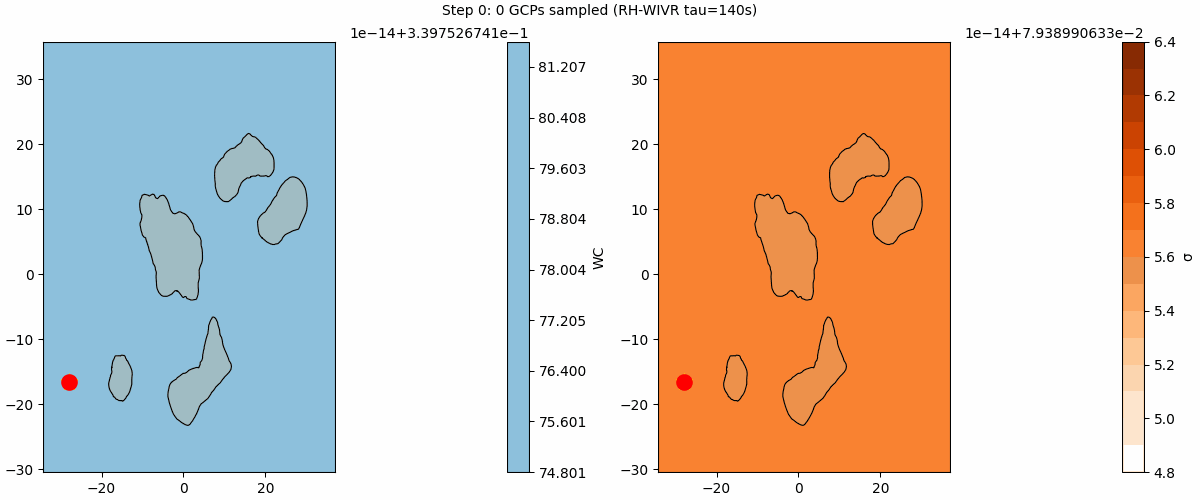

In [19]:
tau_anim=TIME_BUDGETS[-1]
path_anim=rh_results_wivr[tau_anim]["path"]
meas_anim=rh_results_wivr[tau_anim]["measured"]
waypoints=[n for n in path_anim if n!=BASE_NODE]

K_EE_prior=np.full(len(eval_pts_grid),SIGMA2_GIBBS)
l_ev=l_at(d_edge_grid,L_MIN_BEST,L_MAX_BEST); l_no=l_nodes.copy()

def _mission_frame(cond_dict):
    C=sorted(cond_dict.keys())
    if C:
        K_CC=K_all_gibbs[np.ix_(C,C)]+NV_GIBBS_PLAN*np.eye(len(C))
        y_c=np.array([cond_dict[i] for i in C])
        K_EC=gibbs_K(eval_pts_grid,node_coords[C],l_ev,l_no[C],SIGMA2_GIBBS)
        mu_ev=K_EC@np.linalg.solve(K_CC,y_c)
        var_ev=K_EE_prior-np.sum(K_EC*np.linalg.solve(K_CC,K_EC.T).T,axis=1)
    else:
        mu_ev=np.zeros(len(eval_pts_grid)); var_ev=K_EE_prior.copy()
    return mu_ev*y_std+y_mean, np.sqrt(np.maximum(var_ev,1e-12))*y_std

print("Pre-computing mission frames..."); t0_m=time.perf_counter()
mission_frames=[]; cond_so_far={}
mission_frames.append(_mission_frame(cond_so_far))
for wp in waypoints:
    if wp in meas_anim: cond_so_far[wp]=meas_anim[wp]
    mission_frames.append(_mission_frame(cond_so_far))
print(f"  {len(mission_frames)} frames in {time.perf_counter()-t0_m:.1f}s")

vmin_m=min(f[0].min() for f in mission_frames); vmax_m=max(f[0].max() for f in mission_frames)
print("Rendering mission GIF..."); gif_frames2=[]
for fi,(mu_f,std_f) in enumerate(mission_frames):
    fig_m,(ax_mu,ax_std)=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
    for ax_ in (ax_mu,ax_std):
        for geom in pool_bounds.geometry:
            xy2=np.array(geom.exterior.coords)[:,:2]; xs,ys=xy2[:,0],xy2[:,1]
            ax_.fill(xs-cx,ys-cy,alpha=0.3,color="tan",zorder=2)
            ax_.plot(xs-cx,ys-cy,"k-",lw=0.8,zorder=3)
        ax_.scatter([node_xc[0]],[node_yc[0]],marker="*",c="gold",s=150,zorder=8)
    c_mu =ax_mu.contourf( X1g,X2g,mu_f.reshape(X1g.shape), levels=20,cmap="Blues",  vmin=vmin_m,vmax=vmax_m)
    c_std=ax_std.contourf(X1g,X2g,std_f.reshape(X1g.shape),levels=15,cmap="Oranges")
    plt.colorbar(c_mu,ax=ax_mu,label="WC"); plt.colorbar(c_std,ax=ax_std,label="\u03c3")
    path_so_far=path_anim[:fi+1] if fi<len(path_anim) else path_anim
    for a,b in zip(path_so_far[:-1],path_so_far[1:]):
        key=(min(a,b),max(a,b))
        coords=detour_vis_paths.get(key,[(node_xc[a],node_yc[a]),(node_xc[b],node_yc[b])])
        for ax_ in (ax_mu,ax_std):
            ax_.plot([c[0] for c in coords],[c[1] for c in coords],"-",color="red",lw=2,alpha=0.85,zorder=6)
    cur=waypoints[fi-1] if 1<=fi<=len(waypoints) else BASE_NODE
    for ax_ in (ax_mu,ax_std):
        ax_.scatter([node_xc[cur]],[node_yc[cur]],c="red",s=120,zorder=9)
    vis_wp=waypoints[:fi]
    if vis_wp:
        for ax_ in (ax_mu,ax_std):
            ax_.scatter(node_xc[vis_wp],node_yc[vis_wp],c="lime",s=60,zorder=7,edgecolors="k")
    fig_m.suptitle(f"Step {fi}: {fi} GCPs sampled (RH-WIVR tau={tau_anim:.0f}s)",fontsize=10)
    canvas=FigureCanvasAgg(fig_m); canvas.draw()
    buf=io.BytesIO(); canvas.print_png(buf); buf.seek(0)
    gif_frames2.append(PILImage.open(buf).copy()); plt.close(fig_m)

gif_m=os.path.join(RESULTS_DIR,"nb06_mission.gif")
gif_frames2[0].save(gif_m,save_all=True,append_images=gif_frames2[1:],optimize=False,duration=600,loop=0)
print(f"Saved {gif_m}")
with open(gif_m,"rb") as f: b64=base64.b64encode(f.read()).decode()
display(HTML(f'<img src="data:image/gif;base64,{b64}" style="max-width:700px"/>'))


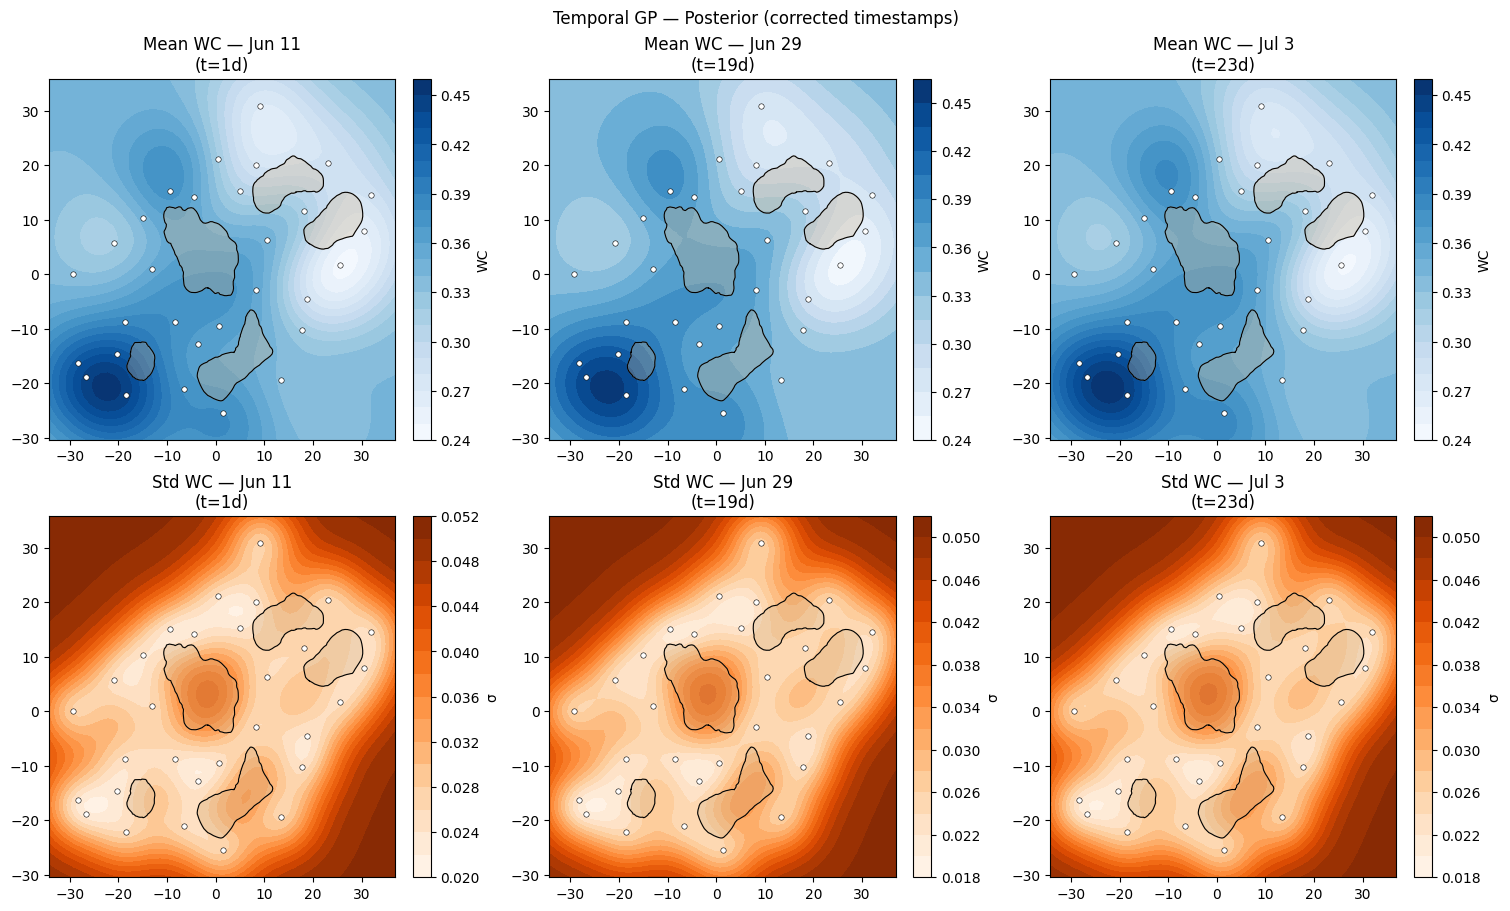

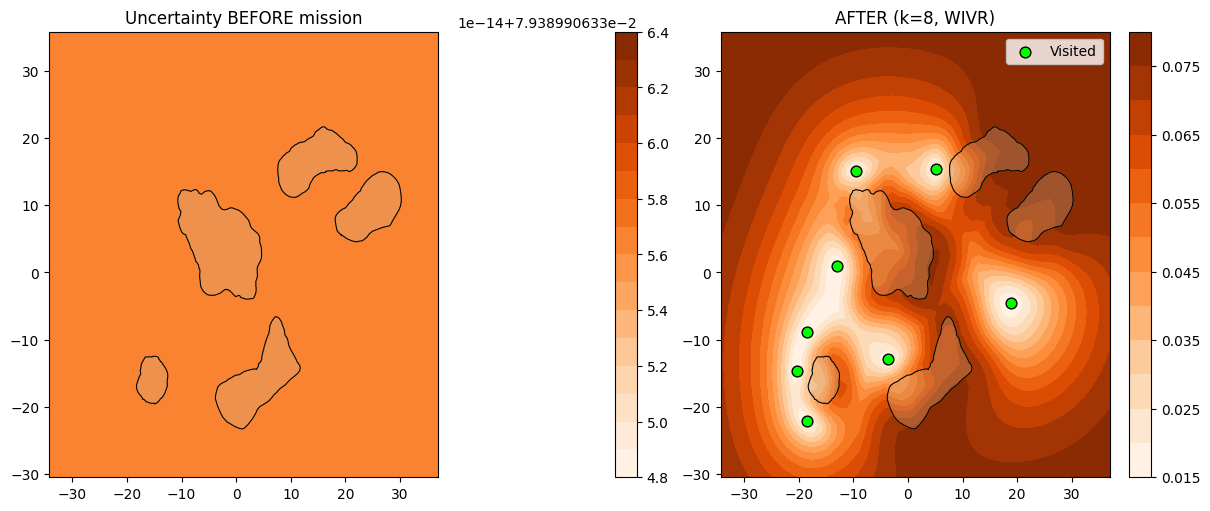

Saved C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning\results\nb06_snapshots.png
Saved C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning\results\nb06_uncertainty_before_after.png


In [20]:
fig_s,axes_s=plt.subplots(2,3,figsize=(15,9),constrained_layout=True)
snap_t=[("Jun 11\n(t=1d)",1.0/T_MAX),("Jun 29\n(t=19d)",float(T_JUN29)/T_MAX),("Jul 3\n(t=23d)",float(T_JUL3)/T_MAX)]
for col_i,(label,t_norm) in enumerate(snap_t):
    X_q=np.column_stack([eval_pts_grid,np.full(len(eval_pts_grid),t_norm)])
    with torch.no_grad():
        pred_q=model_st(torch.tensor(X_q,dtype=torch.float32))
        mu_q=pred_q.mean.numpy()*y_st_std+y_st_mean
        std_q=pred_q.variance.numpy()**0.5*y_st_std
    c_mu=axes_s[0,col_i].contourf(X1g,X2g,mu_q.reshape(X1g.shape), levels=20,cmap="Blues")
    c_sd=axes_s[1,col_i].contourf(X1g,X2g,std_q.reshape(X1g.shape),levels=15,cmap="Oranges")
    for ri in range(2):
        ax_=axes_s[ri,col_i]
        for geom in pool_bounds.geometry:
            xy2=np.array(geom.exterior.coords)[:,:2]; xs,ys=xy2[:,0],xy2[:,1]
            ax_.fill(xs-cx,ys-cy,alpha=0.3,color="tan",zorder=2)
            ax_.plot(xs-cx,ys-cy,"k-",lw=0.8,zorder=3)
        ax_.scatter(node_xc[1:],node_yc[1:],c="w",s=15,zorder=5,edgecolors="k",lw=0.4)
    axes_s[0,col_i].set_title(f"Mean WC — {label}"); axes_s[1,col_i].set_title(f"Std WC — {label}")
    plt.colorbar(c_mu,ax=axes_s[0,col_i],label="WC"); plt.colorbar(c_sd,ax=axes_s[1,col_i],label="\u03c3")
fig_s.suptitle("Temporal GP — Posterior (corrected timestamps)",fontsize=12)
out_s=os.path.join(RESULTS_DIR,"nb06_snapshots.png")
plt.savefig(out_s,dpi=130,bbox_inches="tight"); plt.show()

K_EE_d_prior=np.full(len(eval_pts_grid),SIGMA2_GIBBS)
std_before=np.sqrt(np.maximum(K_EE_d_prior,1e-12))*y_std
_,std_af=mission_frames[-1]
fig_ba,(ax_b,ax_af)=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax_ in (ax_b,ax_af):
    for geom in pool_bounds.geometry:
        xy2=np.array(geom.exterior.coords)[:,:2]; xs,ys=xy2[:,0],xy2[:,1]
        ax_.fill(xs-cx,ys-cy,alpha=0.3,color="tan",zorder=2)
        ax_.plot(xs-cx,ys-cy,"k-",lw=0.8,zorder=3)
c_b=ax_b.contourf(X1g,X2g,std_before.reshape(X1g.shape),levels=15,cmap="Oranges")
c_af=ax_af.contourf(X1g,X2g,std_af.reshape(X1g.shape),levels=15,cmap="Oranges")
vis_wp=[n for n in path_anim if n!=BASE_NODE]
if vis_wp: ax_af.scatter(node_xc[vis_wp],node_yc[vis_wp],c="lime",s=60,zorder=7,edgecolors="k",label="Visited"); ax_af.legend()
ax_b.set_title("Uncertainty BEFORE mission"); ax_af.set_title(f"AFTER (k={len(vis_wp)}, WIVR)")
plt.colorbar(c_b,ax=ax_b); plt.colorbar(c_af,ax=ax_af)
out_ba=os.path.join(RESULTS_DIR,"nb06_uncertainty_before_after.png")
plt.savefig(out_ba,dpi=130,bbox_inches="tight"); plt.show()
print(f"Saved {out_s}"); print(f"Saved {out_ba}")


## Summary

In [21]:
jun_wc_mean = float(june_df['AvgWC'].mean())
j3_wc_mean  = float(jul3_df['AvgWC'].mean())

print()
print("Summary")
print("="*72)
print()
print("Data: 30 GCPs measured across 6 dates between Jun 10 and Jul 3, 2026.")
print("Each GCP has its own measurement date within June. Total: 90 observations.")
print()
print("Temporal GP")
print("-"*40)
print(f"The SpaceTimeGP fit a temporal lengthscale of {ls_days:.0f} days, which is longer")
print(f"than the entire 23-day campaign window. In practice this means the model")
print(f"treats all measurement dates as nearly identical — it is largely a spatial GP")
print(f"that happens to have a time coordinate attached.")
print()
print(f"Extrapolation (holding out a full date, predicting from the others):")
print(f"  Jun 29 held out — GP RMSE {loo_extrap['Jun 29']['gp_rmse']:.4f} vs naive mean {loo_extrap['Jun 29']['naive_rmse']:.4f}.")
print(f"  Jul 3  held out — GP RMSE {loo_extrap['Jul 3']['gp_rmse']:.4f} vs naive mean {loo_extrap['Jul 3']['naive_rmse']:.4f}.")
print(f"  The GP loses to the naive mean on both full-coverage dates, because the field")
print(f"  drifted wetter (Jun mean WC {jun_wc_mean:.3f} → Jul 3 mean {j3_wc_mean:.3f}) and the")
print(f"  temporal model can't resolve that change from only 6 widely-spaced dates.")
print(f"  Within June, the GP wins (Jun 16, Jun 19 held out) — but this is spatial")
print(f"  interpolation from nearby dates, not genuine temporal prediction.")
print()
print(f"Temporal fusion (partial Jul 3 mission + June history):")
print(f"  Fusion was tested at k = {sorted(fusion_results.keys())} GCPs visited today.")
print(f"  Static-partial (today only) beat fusion at all k values. The historical prior")
print(f"  pulls estimates toward the June mean — the wrong direction when the field is wetter.")
print(f"  Recommendation: revisit fusion when more campaign dates are available (ideally")
print(f"  weekly visits over a season) to give the model enough data to learn the change rate.")
print()
print("Non-stationary kernel (Gibbs)")
print("-"*40)
print(f"The Gibbs kernel adapts its spatial lengthscale to geometry: shorter near pool")
print(f"edges (where gradients are steeper) and longer in open upland. Best parameters:")
print(f"  l_min = {L_MIN_BEST:.0f} m (near-edge),  l_max = {L_MAX_BEST:.0f} m (upland)")
print(f"  LOO RMSE: {best_gibbs:.4f}  vs static {loo_rmse_static:.4f}  ({(loo_rmse_static-best_gibbs)/loo_rmse_static*100:.1f}% improvement)")
print(f"  Near pool edges (d < 5 m): Gibbs reduces error meaningfully.")
print(f"  Calibration caveat: NEES = {loo_nees_g:.2f} (above 1.0 means overconfident).")
print(f"  The model fits better than static on point estimates but the uncertainty")
print(f"  intervals are too narrow — worth noting in any paper claims about coverage.")
print()
print("Planning objective (EMSE / WIVR)")
print("-"*40)
print(f"Binney's paper uses variance reduction as its objective, not mutual information.")
print(f"EMSE (expected mean squared error reduction) implements this exactly.")
print(f"WIVR adds pool-edge weighting to steer the planner toward ecologically important zones.")
print(f"Both pass the empirical submodularity check ({sum(r_emse)}/{n_t} and {sum(r_wivr)}/{n_t} triples),")
print(f"so the GRG approximation guarantee applies to both.")
print()
print("Edge sampling")
print("-"*40)
print(f"The implementation is correct and pool-safe ({sum(r['in_pool'] for r in edge_results.values())} midpoints inside pool buffer).")
print(f"On this dataset, node-only paths outperformed paths with edge samples at most budgets.")
print(f"This result is not informative: the GP midpoint prediction is used as ground truth,")
print(f"making the edge measurement a noisy resample of what the model already knew.")
print(f"A meaningful test requires real continuous sensor readings taken along the path.")



Summary

Data: 30 GCPs measured across 6 dates between Jun 10 and Jul 3, 2026.
Each GCP has its own measurement date within June. Total: 90 observations.

Temporal GP
----------------------------------------
The SpaceTimeGP fit a temporal lengthscale of 77 days, which is longer
than the entire 23-day campaign window. In practice this means the model
treats all measurement dates as nearly identical — it is largely a spatial GP
that happens to have a time coordinate attached.

Extrapolation (holding out a full date, predicting from the others):
  Jun 29 held out — GP RMSE 0.0941 vs naive mean 0.0901.
  Jul 3  held out — GP RMSE 0.1157 vs naive mean 0.0971.
  The GP loses to the naive mean on both full-coverage dates, because the field
  drifted wetter (Jun mean WC 0.340 → Jul 3 mean 0.392) and the
  temporal model can't resolve that change from only 6 widely-spaced dates.
  Within June, the GP wins (Jun 16, Jun 19 held out) — but this is spatial
  interpolation from nearby dates, not ge

## What's Left for Future Work

Several directions are not pursued here but are natural next steps:

**Temporal modeling**: The core limitation is that we have too few campaign dates to
estimate how fast the field changes. More frequent visits — ideally weekly — would give
the temporal lengthscale a much better chance to reflect the true rate of seasonal drift.
At that point, fusion-style approaches become worth revisiting.

**Edge sampling with real data**: The implementation is ready; what's needed is a sensor
that records readings continuously along the path between stops, not just at the GCP markers.

**Anisotropic and multi-regime Gibbs kernel**: The current Gibbs kernel varies lengthscale
with distance from pool edges, but the gradient direction may also matter (e.g., north-south
vs east-west differences driven by topography). This would require more training data to
fit reliably.

**Learned or RL planners**: Once a large enough dataset exists across multiple seasons,
learned planners could adapt the mission strategy to observed temporal patterns rather than
relying on a fixed kernel parameterization.
